# Mirzam - Beta Canis Majoris - 06/02/2026 - Line measures

In [1]:
import math
import random as rnd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import curve_fit
from scipy.special import voigt_profile

import warnings
warnings.filterwarnings('ignore')

## Initial configuration

In [2]:
SPECTRUM_FILE_NAME = "_mirzam_20260206_827.fit"

##########################
# Continuum fitting related constants
##########################

EXCLUDED_REGIONS = [(3720,3725),(3730,3740),(3745,3752),(3767,3773),(3795,3805),(3820,3850),(3880,3900),(3950,3990),(4060,4130),(4330,4355),(4840,4870),(6450,6500),(6515,6590)]

SIGMALO_RANGE=(1.70, 2.2)
SIGMAHI_RANGE=(9.90,10.10)
DEGREE_RANGE = (6,14)

##########################
# Noise evaluation related constants
##########################

NOISE_EVALUATION_WINDOW = (5500,5600)
NOISE_CONTINUUM_WINDOW = (5200,5800)

NOISE_CONTINUUM_DEGREE = 10 # Degree of the polynomial used to fit the continuum in the noise evaluation window

##########################
# Line fitting related constants
##########################

GAUSS_FIT_WINDOW = 3 # in FWHM units
VOIGT_FIT_WINDOW = 3 # in FWHM units

GAUSSIAN_FIT_PLOT_WINDOW = 2.25    # In FWHM units
VOIGT_FIT_PLOT_WINDOW = 4.0        # In FWHM units

#############################
# Lines fit bounds
#############################

GAUSS_LAMBDA_WIN = 3.0  # In angstrom
VOIGT_LAMBDA_WIN = 3.0  # In angstrom

GAUSS_AMP_MIN = -1.5
GAUSS_AMP_MAX = 0.0

GAUSS_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
GAUSS_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

VOIGT_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
VOIGT_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

INSTR_RESOLUTION = 850    # R = lambda/delta_lambda

MONTECARLO_SAMPLES = 2500

ADD_NOISE = True

REMOVE_WORST_FITS = True
WORST_FIT_SIGMA_TO_REMOVE = 4
#WORST_FIT_PERC_TO_REMOVE = 50

SHOW_PARAM_DEPENDENCIES = False

## List of lines

In [3]:
measuring_lines = [{
    "name": "H alfa",
    "model": "voigt",
    "central_wl": 6563.0,
    "winlo_range":(6300.0,6400.0),
    "winhi_range":(6675.0,6775.0)
    },
                   {
    "name": "H beta",
    "model": "voigt",
    "central_wl": 4861.0,
    "winlo_range":(4550.0,4700.0),
    "winhi_range":(5100.0,5350.0)
    },
                   {
    "name": "He I 4009",
    "model": "gauss",
    "central_wl": 4009.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4075.0,4200.0)
    },
                   {
    "name": "He I 4026",
    "model": "gauss",
    "central_wl": 4026.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4100.0,4250.0)
    },
                   {
    "name": "He I 4388",
    "model": "gauss",
    "central_wl": 4388.0,
    "winlo_range":(4050.0,4225.0),
    "winhi_range":(4400.0,4550.0)
    },
                   {
    "name": "He I 4922",
    "model": "gauss",
    "central_wl": 4922.0,
    "winlo_range":(4650.0,4800.0),
    "winhi_range":(5000.0,5150.0)
    },
                   {
    "name": "He I 6678",
    "model": "gauss",
    "central_wl": 6678.0,
    "winlo_range":(6350.0,6630.0),
    "winhi_range":(6750.0,6875.0)
    }
]

In [4]:
measuring_blends = [{
    "name": "He I/Mg II 4471-81",
    "central_wls": [{"name": "He I 4471",    "wavelength": 4471.0}, 
                    {"name": "Mg II 4481",   "wavelength": 4481.0}, 
                    {"name": "Unknown 4490", "wavelength": 4490.0}],
    "winlo_range":(4200.0,4325.0),
    "winhi_range":(4500.0,4625.0)
    },
                    {
    "name": "He I 4713",
    "central_wls": [{"name": "O II 4699",    "wavelength": 4699.0}, 
                    {"name": "O II 4705",    "wavelength": 4705.0}, 
                    {"name": "He I 4713",    "wavelength": 4713.0}],
    "winlo_range":(4500.0,4625.0),
    "winhi_range":(4800.0,5050.0)
    },
                    {
    "name": "H delta / He I 4121-4144",
    "central_wls": [{"name": "O II 4072",    "wavelength": 4072.0}, 
                    {"name": "O II 4076",    "wavelength": 4076.0},
                    {"name": "O II 4089",    "wavelength": 4089.0},
                    {"name": "H delta",      "wavelength": 4101.0, "model": "voigt"},
                    {"name": "He I 4121",    "wavelength": 4121.0}, 
                    {"name": "O II 4133",    "wavelength": 4133.0}, 
                    {"name": "He I 4144",    "wavelength": 4144.0},
                    {"name": "Unknown 4153", "wavelength": 4153.0}],
    "winlo_range":(3800.0,3950.0),
    "winhi_range":(4200.0,4350.0)
    },
                    {
    "name": "H gamma",
    "central_wls": [{"name": "H gamma",         "wavelength": 4341.0, "model": "voigt"}, 
                    {"name": "O II 4349",       "wavelength": 4349.0}],
    "winlo_range":(4000.0,4225.0),
    "winhi_range":(4475.0,4600.0)
    }
]

## Load spectrum

In [5]:
def load_spectrum(path):
    with fits.open(path) as hdul:
        hdr = hdul[0].header
        flux = hdul[0].data.astype(float)
        wl = hdr['CRVAL1'] + hdr['CDELT1'] * np.arange(hdr['NAXIS1'])
    good = flux > 0                      # drop the zeroed/bad pixels
    return wl[good], flux[good]

In [6]:
wl, flux = load_spectrum(SPECTRUM_FILE_NAME)

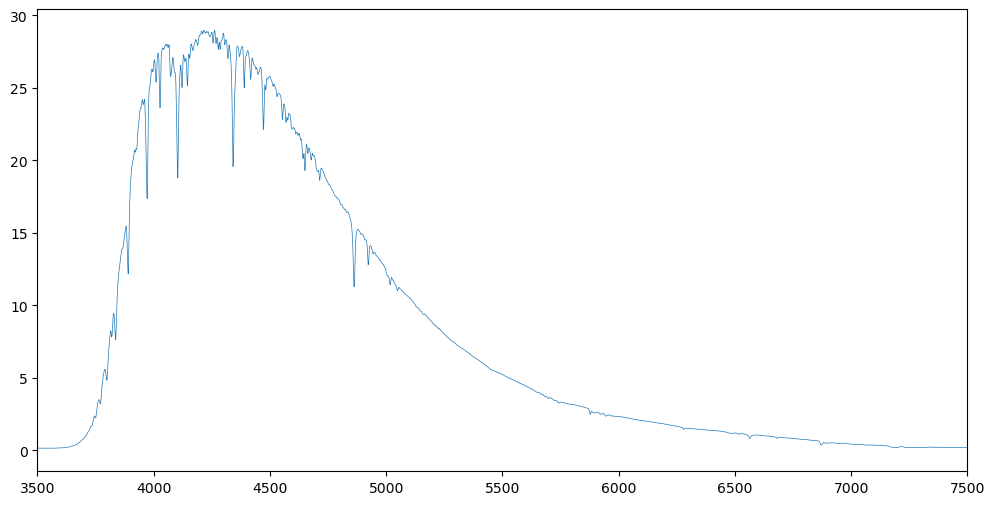

In [7]:
plt.figure(figsize=(12,6))
plt.plot(wl, flux, lw=0.5)
#plt.ylim(ymin, ymax)
plt.xlim(3500,7500)
plt.show()

## Continuum related procedures

In [8]:
def robust_continuum_fit(x, y, exclude_windows, degree, sigma_lo=3.0, sigma_hi=3.0, max_iter=20):
    seed = np.ones(len(x), dtype=bool)
    for lo, hi in exclude_windows:
        seed &= ~((x >= lo) & (x <= hi))
    xc = x - x.mean()
    mask = seed.copy()
    for i in range(max_iter):
        p = np.polyfit(xc[mask], y[mask], degree)
        resid = y - np.polyval(p, xc)
        s = resid[mask].std()
        new_mask = seed & (resid > -sigma_lo * s) & (resid < sigma_hi * s)
        if np.array_equal(new_mask, mask):
            break
        mask = new_mask
    return p, x.mean(), mask

In [9]:
def rectify_zone(wl, flux, zone, plot=False, degree=7, max_iter=20, sigma_lo=1.5, sigma_hi=10.0):
    zone_min, zone_max = zone
    enlarged_zone_min = zone_min - 50
    enlarged_zone_max = zone_max + 50

    mw = (wl >= enlarged_zone_min) & (wl <= enlarged_zone_max)
    p, wlmean, mask = robust_continuum_fit(wl[mw], flux[mw], EXCLUDED_REGIONS, degree, max_iter=max_iter, sigma_lo=sigma_lo, sigma_hi=sigma_hi)
    cont = np.polyval(p, wl - wlmean)[mw]

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl[mw], flux[mw], lw=0.5)
        plt.plot(wl[mw], cont, lw=0.5)
        #plt.ylim(ymin, ymax)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum fit")
        plt.show()    

    rect3 = flux[mw] / cont
    wl3 = wl[mw]
    mw = (wl3 >= zone_min) & (wl3 <= zone_max)
    rect3 = rect3[mw]
    wl3 = wl3[mw]  

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl3, rect3, lw=0.5)
        #plt.ylim(0.7, 1.05)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum calibrated spectrum")
        plt.show()

    return wl3, rect3

## Noise evaluation

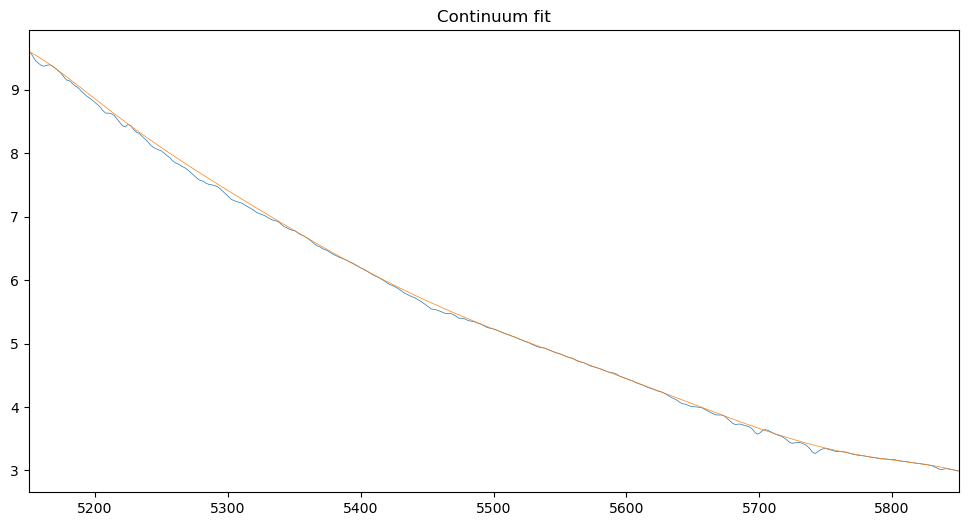

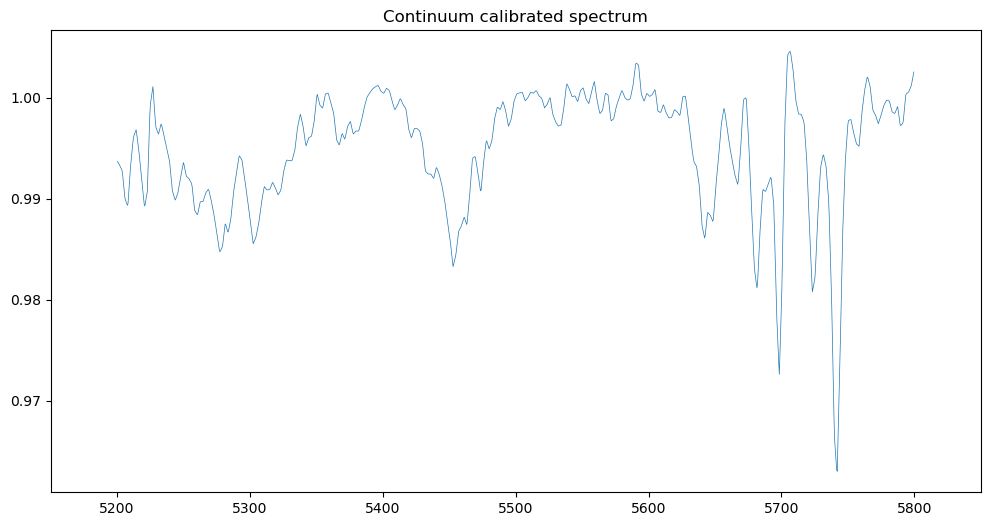

Noise =  0.000680023379064852 Flux at eval window =  4.838986873626709 SNR =  7115.912515068439


In [10]:
continuum_mask = (wl > NOISE_CONTINUUM_WINDOW[0]) & (wl < NOISE_CONTINUUM_WINDOW[1])
wlzone, rectzone = rectify_zone(wl, flux, NOISE_CONTINUUM_WINDOW, degree=NOISE_CONTINUUM_DEGREE, plot=True)
evaluation_mask = (wlzone > NOISE_EVALUATION_WINDOW[0]) & (wlzone < NOISE_EVALUATION_WINDOW[1])
noise = 1.4826 * np.median(
        np.abs(rectzone[evaluation_mask] - np.median(rectzone[evaluation_mask]))
    )
noise_evaluation_flux = np.median(flux[continuum_mask][evaluation_mask])
snr = noise_evaluation_flux / noise
print("Noise = ",noise, "Flux at eval window = ", noise_evaluation_flux, "SNR = ", snr)

## Line Fitting procedures

In [11]:
def gaussian_model(x, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + offset
    
    

def voigt_model(x, amp, mean, sigma, gamma, offset):
    # voigt_profile(x - mean, sigma, gamma) è normalizzata a area = 1
    return amp * voigt_profile(x - mean, sigma, gamma) + offset

In [12]:
def plot_gauss_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, gaussian_model(w, *popt), "r", label="Gaussian fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [13]:
def calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm):
    wl_min = mu - fwhm
    wl_max = mu + fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - gaussian_model(res_w, amp, mu, sigma, offset)) ** 2)/gaussian_model(res_w, amp, mu, sigma, offset)).sum()

In [14]:
def fit_line_gaussian(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, median_continuum]
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355]
    #if plot:
    #    print("initial guess", p0)
    fit_wl_min = lam_expected - GAUSS_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + GAUSS_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    try:
        # popt, _ = curve_fit(gaussian_model, w, f, p0=p0)
        bounds_lo = [ GAUSS_AMP_MIN * amp0, lam_expected - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * fwhm_expected / 2.355]
        bounds_hi = [ GAUSS_AMP_MAX * amp0, lam_expected + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * fwhm_expected / 2.355]
        popt, _ = curve_fit(
            lambda x, a, m, s: gaussian_model(x, a, m, s, offset),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
        #amp, mu, sigma, offset = popt
        amp, mu, sigma = popt
            
        sigma_nom = abs(sigma)
        fwhm_fit = 2.355 * sigma_nom
        fwhm_nom = fwhm_fit #np.clip(fwhm_fit, 0.7 * fwhm_instr, 1.5 * fwhm_instr)
        ew_nom = np.sqrt(2 * np.pi) * abs(amp) * sigma_nom / offset

        chi2 = calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 = ",chi2)
            plot_mask = (w >= mu-GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom)
            plot_gauss_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        amp = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, amp, chi2)

In [15]:
def plot_voigt_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, voigt_model(w, *popt), "r", label="Voigt fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [16]:
def calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm):
    wl_min = mu - 2 * fwhm
    wl_max = mu + 2 * fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - voigt_model(res_w, amp, mu, sigma, gam, offset))**2)/voigt_model(res_w, amp, mu, sigma, gam, offset)).sum()

In [17]:
def fit_line_voigt(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):
    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355]
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355, offset]
    fit_wl_min = lam_expected - VOIGT_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + VOIGT_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    #if plot:
    #    print("initial guess", p0)
    try:
        #popt, _ = curve_fit(voigt_model, w, f, p0=p0)
        popt, _ = curve_fit(
            lambda x, a, m, s, g: voigt_model(x, a, m, s, g, offset),
            w,
            f,
            p0 = p0)
        #amp, mu, sigma, gam, offset = popt
        amp, mu, sigma, gam = popt
        #sigma_nom = abs(sigma)

        intensity = amp * voigt_profile(0.0, sigma, gam)
        
        f_g = 2 * sigma * np.sqrt(2 * np.log(2))
        f_l = 2 * gam
        fwhm_nom = 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)
        
        ew_nom = abs(amp)/offset

        chi2 = calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            plot_mask = (w >= mu-VOIGT_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+VOIGT_FIT_PLOT_WINDOW*fwhm_nom)
            plot_voigt_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, gam, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        intensity = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, intensity, chi2)

In [18]:
# Number of fit parameters used by each component model:
#   gauss : amp (line depth), mu, sigma
#   voigt : amp (area),       mu, sigma, gamma
PARAMS_PER_MODEL = {"gauss": 3, "voigt": 4}


def normalize_model_name(line):
    """Return 'gauss' or 'voigt' for a blend component dict (default: 'gauss')."""
    model = str(line.get("model", "gauss")).strip().lower()
    if model in ("gauss", "gaussian"):
        return "gauss"
    if model == "voigt":
        return "voigt"
    raise ValueError(f"Unknown model '{line.get('model')}' for blend component "
                     f"'{line.get('name')}': use 'gauss' or 'voigt'")


def voigt_fwhm(sigma, gamma):
    # Olivero & Longbothum approximation (same formula used by fit_line_voigt)
    f_g = 2 * sigma * np.sqrt(2 * np.log(2))
    f_l = 2 * gamma
    return 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)


def component_profile(x, model, params):
    """Profile of a single blend component, WITHOUT the continuum offset."""
    if model == "voigt":
        amp, mu, sigma, gamma = params
        return amp * voigt_profile(x - mu, sigma, gamma)
    amp, mu, sigma = params
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def split_blend_params(models, params):
    """Split the flat parameter vector into one tuple per component."""
    result = []
    k = 0
    for model in models:
        n = PARAMS_PER_MODEL[model]
        result.append(tuple(params[k:k + n]))
        k += n
    return result


def multi_line_model(x, offset, models, *params):
    """Sum of gaussian / voigt components (one entry of `models` per component) + continuum."""
    model = np.zeros_like(x, dtype=float)
    for m, p in zip(models, split_blend_params(models, params)):
        model += component_profile(x, m, p)
    return model + offset

In [19]:
def multi_line_initial_guess(lines, wavelength, flux):
    """Initial guess and bounds for a blend of gaussian / voigt components.

    `lines` is the list of component dicts ("wavelength" and optionally "model").
    """
    p0 = []
    bounds_lo = []
    bounds_hi = []
    for line in lines:
        model = normalize_model_name(line)
        lam0 = line["wavelength"]
        peak_index = np.argmin(np.abs(wavelength - lam0))
        depth0 = min(flux[peak_index] - 1.0, 0.0)
        fwhm_instr = lam0 / INSTR_RESOLUTION
        sigma_instr = fwhm_instr / 2.355

        if model == "gauss":
            p0 += [depth0, lam0, sigma_instr]
            bounds_lo += [GAUSS_AMP_MIN, lam0 - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * sigma_instr]
            bounds_hi += [GAUSS_AMP_MAX, lam0 + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * sigma_instr]
        else:
            # Voigt amplitude is the (normalised) area, i.e. -EW for a continuum of 1.
            # Convert the observed depth to an area using the starting profile shape.
            gamma0 = 0.5 * sigma_instr
            amp0 = depth0 / voigt_profile(0.0, sigma_instr, gamma0)
            # Same limits as the gaussian, expressed as areas (depth * width)
            area_scale = np.sqrt(2 * np.pi) * 4.0 * sigma_instr
            amp_lo, amp_hi = -1.5 * area_scale, 0.5 * area_scale
            p0 += [float(np.clip(amp0, amp_lo, amp_hi)), lam0, sigma_instr, gamma0]
            bounds_lo += [amp_lo, lam0 - VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MIN * sigma_instr, 0.0]
            bounds_hi += [amp_hi, lam0 + VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MAX * sigma_instr, 4.0 * sigma_instr]

    return (p0, bounds_lo, bounds_hi)

In [20]:
def plot_multi_line_fit(w, f, popt, models, component, name):
    """Plot data, total blend fit and the component called `name`.

    `component` is the (model, params) pair of the component to highlight.
    """
    comp_model, comp_params = component
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, multi_line_model(w, 1.0, models, *popt), "r", label="Blend fit")
    plt.plot(w, component_profile(w, comp_model, comp_params) + 1.0, "y",
             label=f"{name} ({comp_model})")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [21]:
def fit_blend_group(wavelength, flux, lines, plot=False):
    lams_expected = [l.get("wavelength") for l in lines]
    models = [normalize_model_name(l) for l in lines]
    wl_lam_min = min(lams_expected)
    wl_lam_max = max(lams_expected)
    wl_min = wl_lam_min - 2.5*(wl_lam_max - wl_lam_min)/2.0
    wl_max = wl_lam_max + 2.5*(wl_lam_max - wl_lam_min)/2.0
    
    mask = (wavelength > wl_min) & (wavelength < wl_max)
    
    w = wavelength[mask]
    f = flux[mask]
    offset = 1.0
    
    p0, bounds_lo, bounds_hi = multi_line_initial_guess(lines, w, f)
    
    popt, _ = curve_fit(
            lambda x, *params: multi_line_model(x, offset, models, *params),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
    
    # One parameter tuple per component (3 values for gauss, 4 for voigt)
    component_results = split_blend_params(models, popt)

    chi2 = (((multi_line_model(w, offset, models, *popt) - f) ** 2)/multi_line_model(w, offset, models, *popt)).sum()
    
    final_results = []
    
    for line, model, params in zip(lines, models, component_results):
        if model == "voigt":
            amp, mu, sigma, gam = params
            fwhm_nom = voigt_fwhm(sigma, gam)
            ew_nom = abs(amp) / offset
            intensity = amp * voigt_profile(0.0, sigma, gam)
        else:
            amp, mu, sigma = params
            fwhm_nom = 2.355 * abs(sigma)
            ew_nom = np.sqrt(2 * np.pi) * abs(amp) * abs(sigma) / offset
            intensity = amp
        
        final_results.append((line["name"], mu, ew_nom, fwhm_nom, intensity, chi2))
        
        if plot:
            print(line["name"], f"({model})")
            if model == "voigt":
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            else:
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 =",chi2)
            plot_multi_line_fit(w, f, popt, models, (model, params), line["name"])
        
    return final_results

## Functions for error on continuum placement

In [22]:
def fit_varying_continuum(wl, flux, model, expected_lam, expected_width, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    results = pd.DataFrame(columns=("sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","wavelength","ew","fwhm","intensity","chi2"))
    for i in range(1,MONTECARLO_SAMPLES):
        try:
            sigma_lo = rnd.uniform(*sigma_lo_range)
            sigma_hi = rnd.uniform(*sigma_hi_range)
            degree = rnd.randrange(*degree_range)
            maxiter = rnd.randrange(*maxiter_range)
            win = (rnd.uniform(*winlo_range), rnd.uniform(*winhi_range))
            if add_noise:
                win_mask = (wl > win[0]) & (wl < win[1])
                rescaled_noise = noise * np.sqrt(np.median(flux[win_mask])*noise_evaluation_flux)
                noised_flux = (flux + np.random.normal(0, rescaled_noise, size=len(flux)))
                wlzone, rectzone = rectify_zone(wl, noised_flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            else:
                wlzone, rectzone = rectify_zone(wl, flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            if (model == "voigt"):
                lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=False)
            else:
                lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=False)
            results.loc[i] = pd.Series({"sigma_lo":sigma_lo, "sigma_hi":sigma_hi, "degree":degree, "maxiter":maxiter, "win_lo":win[0], "win_hi":win[1], "wavelength":lam, "ew":ew, "fwhm":fwhm, "intensity":amp, "chi2": chi2})
        except Exception as e:
            print(e)

    if REMOVE_WORST_FITS:
        for i in range(1,20):
            m_res = results["chi2"].mean()
            s_res = results["chi2"].std()
            results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        #chi2_cutoff = results["chi2"].quantile(1.0 - WORST_FIT_PERC_TO_REMOVE/100.0)
        #results = results[results["chi2"] <= chi2_cutoff]

    m = results["ew"].mean()
    results["ew_dist"] = abs(results["ew"] - m)
    
    return results

In [23]:
def refit_with_best(column, results, wl, flux, model, expected_lam, expected_width, plot=False, name=""):
    sort_col = column + "_dist"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = best["degree"]
    maxiter = best["maxiter"].astype(int)
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=plot, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    if (model == "voigt"):
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    return (lam, ew, fwhm, amp)

In [24]:
def fit_blend_varying_continuum(wl, flux, blended_lines, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    results = pd.DataFrame(columns=("sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","record","line","wavelength","ew","fwhm","intensity","chi2"))
    j = 0
    for i in range(1,MONTECARLO_SAMPLES):
        try:
            sigma_lo = rnd.uniform(*sigma_lo_range)
            sigma_hi = rnd.uniform(*sigma_hi_range)
            degree = rnd.randrange(*degree_range)
            maxiter = rnd.randrange(*maxiter_range)
            win = (rnd.uniform(*winlo_range), rnd.uniform(*winhi_range))
            if add_noise:
                win_mask = (wl > win[0]) & (wl < win[1])
                rescaled_noise = noise * np.sqrt(np.median(flux[win_mask])*noise_evaluation_flux)
                noised_flux = (flux + np.random.normal(0, rescaled_noise, size=len(flux)))
                wlzone, rectzone = rectify_zone(wl, noised_flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            else:
                wlzone, rectzone = rectify_zone(wl, flux, win, plot=False, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
            blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=False)
            for line_result in blend_results:
                name, lam_detected, ew, fwhm, amp, chi2 = line_result
                results.loc[j] = pd.Series({"sigma_lo":sigma_lo, "sigma_hi":sigma_hi, "degree":degree, "maxiter":maxiter, "win_lo":win[0], "win_hi":win[1], "record":i, "line":name, "wavelength":lam_detected, "ew":ew, "fwhm":fwhm, "intensity":amp, "chi2": chi2})            
                j = j + 1
        except Exception as e:
            print(e)

    results["ew_dist"] = (results["ew"] - results.groupby("line")["ew"].transform("mean")).abs()
    results["ew_dist_ssq"] = (results["ew_dist"]**2).groupby(results["record"]).transform("sum")

    if REMOVE_WORST_FITS:
        #for i in range(1,20):
        #    s = results["ew_dist_ssq"].std()
        #    results = results[results["ew_dist_ssq"] <= 10*s]
        for i in range(1,20):
            m_res = results["chi2"].mean()
            s_res = results["chi2"].std()
            results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        #chi2_cutoff = results["chi2"].quantile(1.0 - WORST_FIT_PERC_TO_REMOVE/100.0)
        #results = results[results["chi2"] <= chi2_cutoff]
    
    return results

In [25]:
def refit_blend_with_best(column, results, wl, flux, blended_lines, expected_width, plot=False, name=""):
    sort_col = column + "_dist_ssq"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = best["degree"]
    maxiter = best["maxiter"]
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=True, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=True)

## Complete measure procedures

In [26]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [27]:
from IPython.display import Markdown
from IPython.display import display

def measure_line(wl, flux, measuring_line, show_param_dependencies=False):
    name = measuring_line["name"]
    
    display(Markdown(f"### Measuring {name}"))
    model = measuring_line["model"]
    central_wl = measuring_line["central_wl"]
    winlo_range = measuring_line["winlo_range"]
    winhi_range = measuring_line["winhi_range"]
    
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    if model == "voigt":
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_varying_continuum(wl, flux, model, central_wl, fwhm, winlo_range=winlo_range, winhi_range=winhi_range, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux)

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
    plt.subplots_adjust(wspace=0.5, hspace=0.5)
    
    m_ew = results["ew"].mean()
    s_ew = results["ew"].std()
    results.plot.hist(column=["ew"], title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
    m_fwhm = results["fwhm"].mean()
    s_fwhm = results["fwhm"].std()
    results.plot.hist(column=["fwhm"], title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
    
    m_wl = results["wavelength"].mean()
    s_wl = results["wavelength"].std()
    results.plot.hist(column=["wavelength"], title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])
    
    m_amp = results["intensity"].mean()
    s_amp = results["intensity"].std()
    results.plot.hist(column=["intensity"], title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
    
    plt.show()

    display(Markdown(f"#### {name} re-fit with best parameters"))
    lam, ew, fwhm, amp = refit_with_best("ew", results, wl, flux, model, central_wl, m_fwhm, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))
        results["win_size"] = results["win_hi"] - results["win_lo"]
        results["dist"] = abs(results["ew"] - m_ew)

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        sorted_results = results.sort_values(by=["dist"], ascending=True)
        sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
        sorted_results.plot(x="dist", y="degree", ylim=(2,15))
        sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
        sorted_results.plot(x="dist", y="win_size", ylim=(400,800))
        
        results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
        results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
        
        sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
        sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
        plt.show()
    
    return pd.Series({"line_name":name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity": m_amp, "delta_intensity": s_amp})

In [28]:
def measure_blend(wl, flux, measuring_blend, show_param_dependencies=False):
    name = measuring_blend["name"]
    
    display(Markdown(f"### Measuring {name}"))
    blended_lines = measuring_blend["central_wls"]
    winlo_range = measuring_blend["winlo_range"]
    winhi_range = measuring_blend["winhi_range"]
    print("Blended lines=", blended_lines)
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    fit_blend_group(wlzone, rectzone, blended_lines, plot=True)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_blend_varying_continuum(wl, flux, blended_lines, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux, winlo_range=winlo_range, winhi_range=winhi_range)

    blend_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))
    i = 0
    for line in blended_lines:
        line_name = line["name"]
        display(Markdown(f"#### Plotting results for {line_name}"))
        line_results = results[results["line"] == line["name"]]

        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
        plt.subplots_adjust(wspace=0.5, hspace=0.5)
        
        m_ew = line_results["ew"].mean()
        s_ew = line_results["ew"].std()
        line_results.plot.hist(column=["ew"], figsize=(12,6), title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
        m_fwhm = line_results["fwhm"].mean()
        s_fwhm = line_results["fwhm"].std()
        line_results.plot.hist(column=["fwhm"], figsize=(12,6), title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
        
        m_wl = line_results["wavelength"].mean()
        s_wl = line_results["wavelength"].std()
        line_results.plot.hist(column=["wavelength"], figsize=(12,6), title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])

        m_amp = line_results["intensity"].mean()
        s_amp = line_results["intensity"].std()
        line_results.plot.hist(column=["intensity"], figsize=(12,6), title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
        plt.show()
    
        # print("Mean:", m_ew)
        # print("Std Dev:",s_ew)

        line_results = pd.Series({"line_name":line_name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity":m_amp, "delta_intensity":s_amp})
        blend_results.loc[i] = line_results
        i = i + 1

    display(Markdown(f"#### {name} re-fit with best parameters"))
    refit_blend_with_best("ew", results, wl, flux, blended_lines, m_fwhm, plot=True, name=name)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        for line in blended_lines:
            print("Plotting results for ",line["name"])
            line_results = results[results["line"] == line["name"]]
        
            m = line_results["ew"].mean()
            
            line_results["win_size"] = line_results["win_hi"] - line_results["win_lo"]
            line_results["dist"] = abs(line_results["ew"] - m)
            
            sorted_results = line_results.sort_values(by=["dist"], ascending=True)
            sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
            sorted_results.plot(x="dist", y="degree", ylim=(2,15))
            sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
            sorted_results.plot(x="dist", y="win_size", ylim=(250,800))
            
            line_results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
            line_results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
            
            sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
            sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
            plt.show()
            
    return blend_results

## Measure All Lines

### Measuring H alfa

#### H alfa preliminary fit

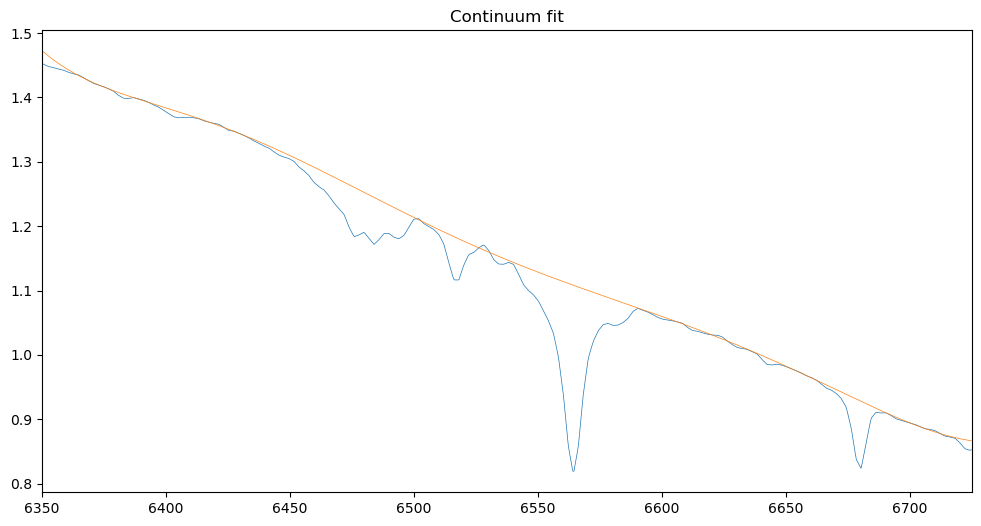

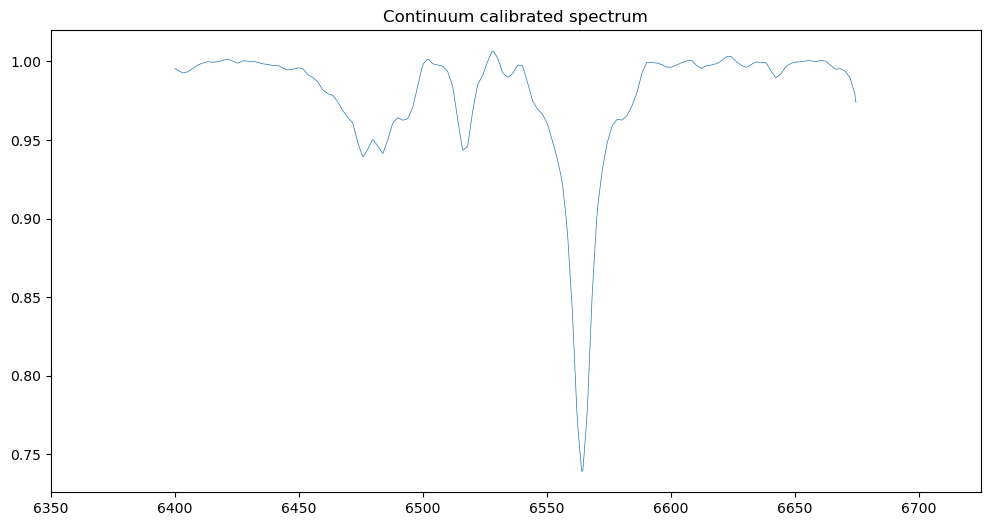

amp = -4.151243216173752 
mu = 6564.135708037765 
sigma = 0.00010821554315594247 
gamma = 5.173619454628556 
offset = 1.0 
chi2 = 0.0021230261708616877


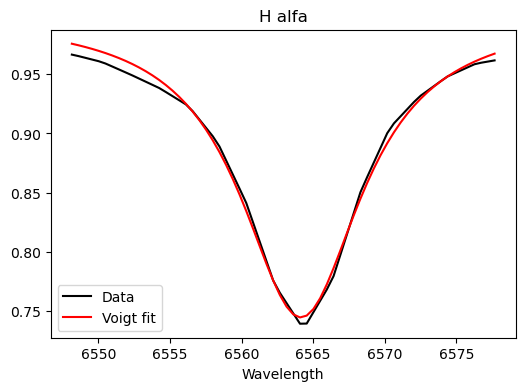

Lambda =  6564.135708037765 Eq Width = 4.151243216173752 FWHM =  10.347270486758134 Intensity =  -0.2554076051923786


#### H alfa optimization

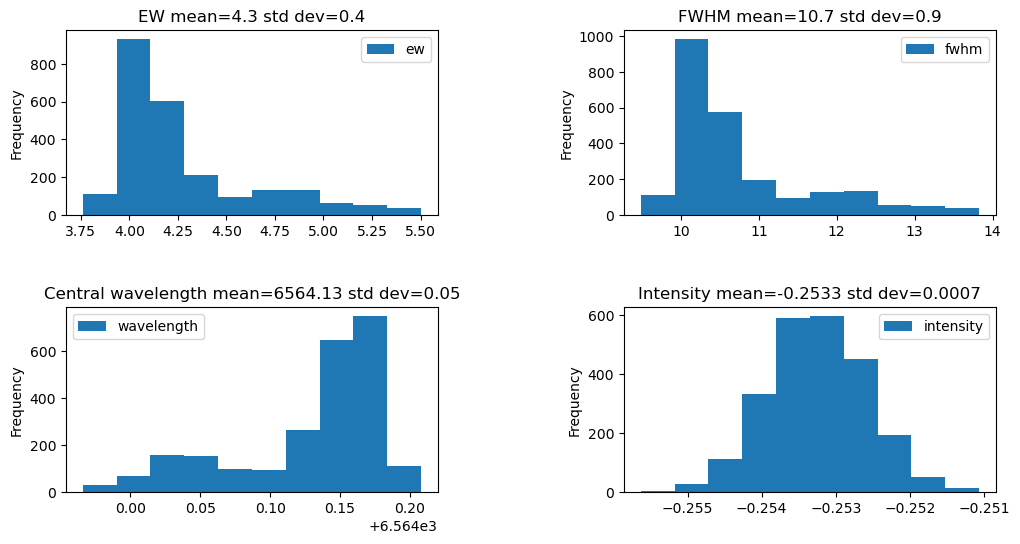

#### H alfa re-fit with best parameters

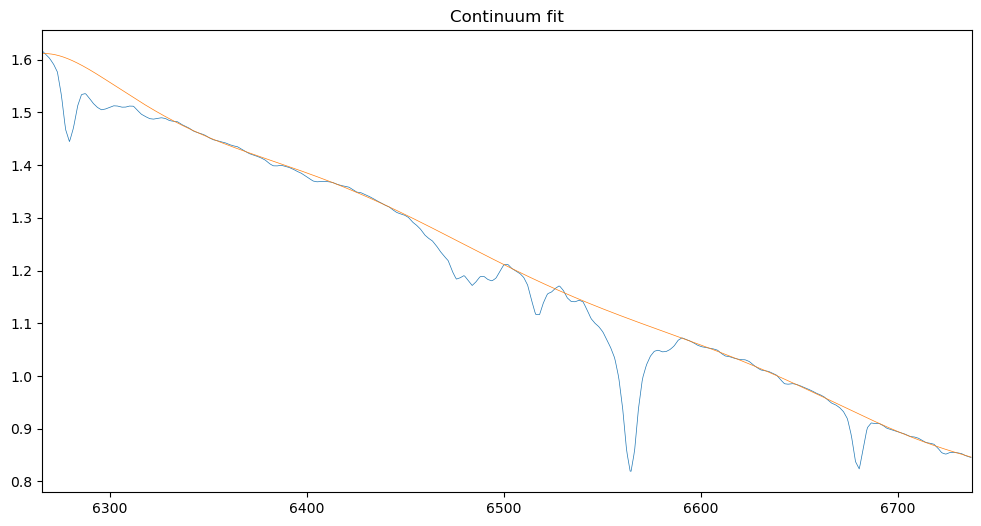

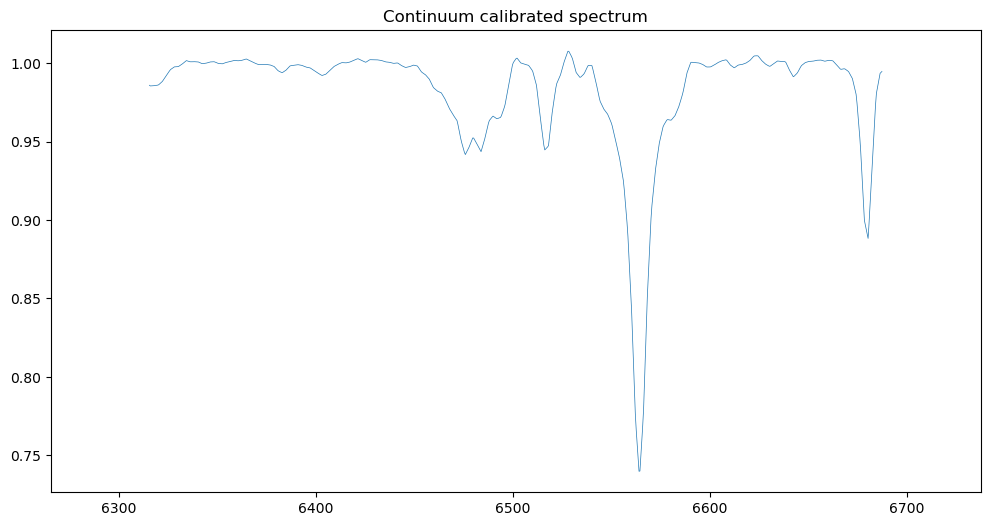

amp = -4.17291951498185 
mu = 6564.14697864153 
sigma = 0.0005511128222406556 
gamma = 5.238540954088262 
offset = 1.0 
chi2 = 0.004872519013370138


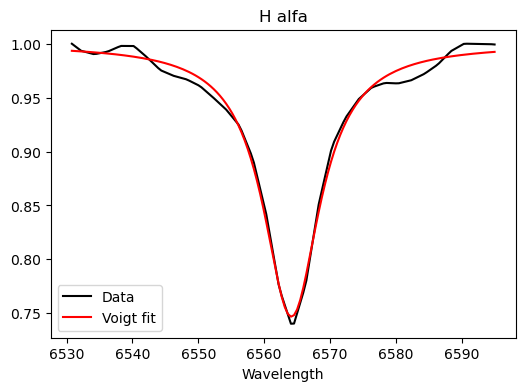

Lambda =  6564.14697864153 Eq Width = 4.17291951498185 FWHM =  10.477114047804733 Intensity =  -0.2535594419912386


### Measuring H beta

#### H beta preliminary fit

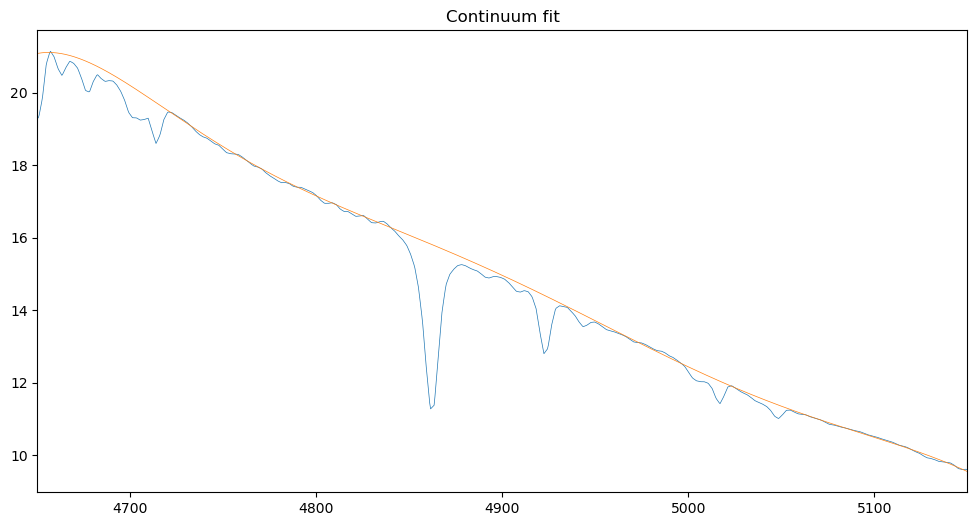

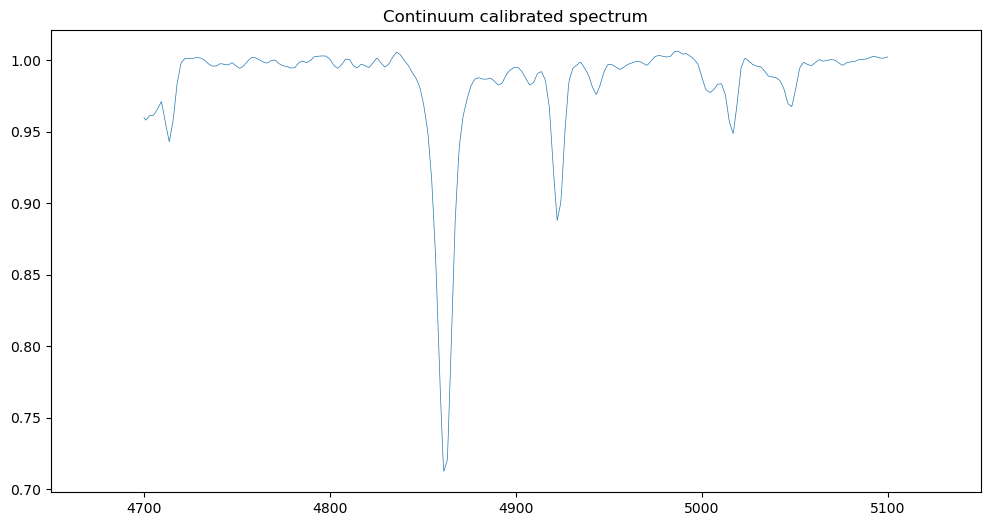

amp = -4.2677866619700895 
mu = 4861.545927534887 
sigma = 2.720830423779636e-05 
gamma = 6.214317676848496 
offset = 1.0 
chi2 = 0.077740516858351


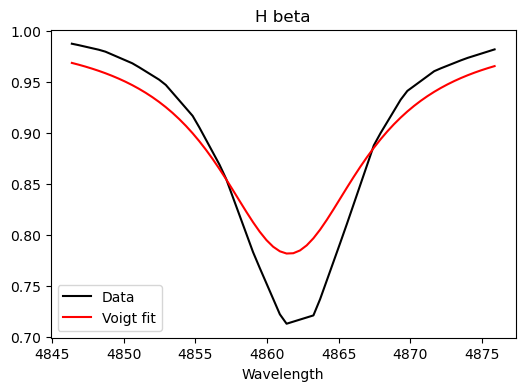

Lambda =  4861.545927534887 Eq Width = 4.2677866619700895 FWHM =  12.428673275419154 Intensity =  -0.21860464128883914


#### H beta optimization

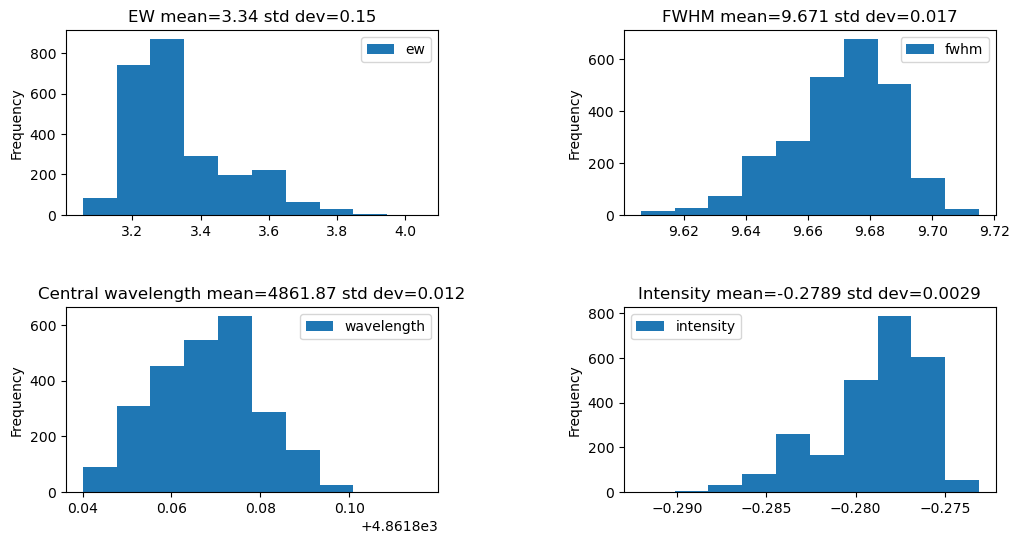

#### H beta re-fit with best parameters

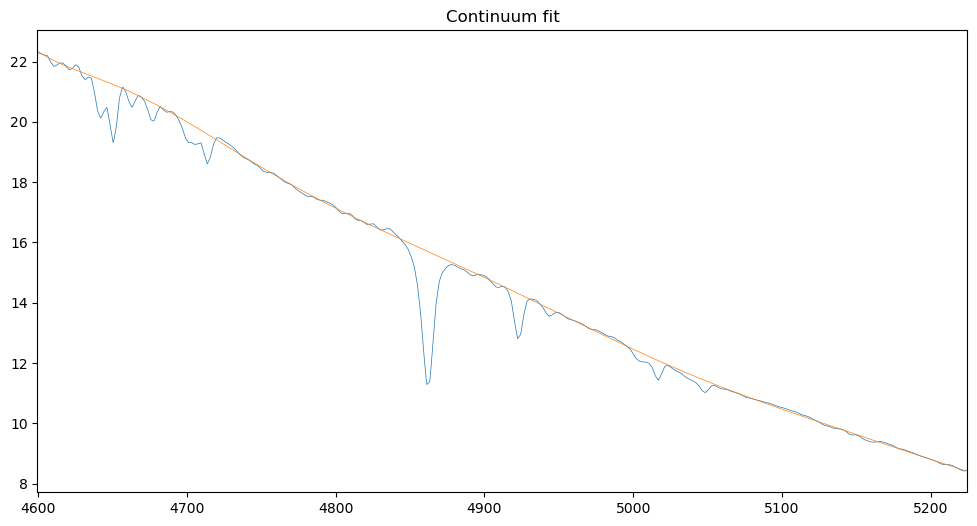

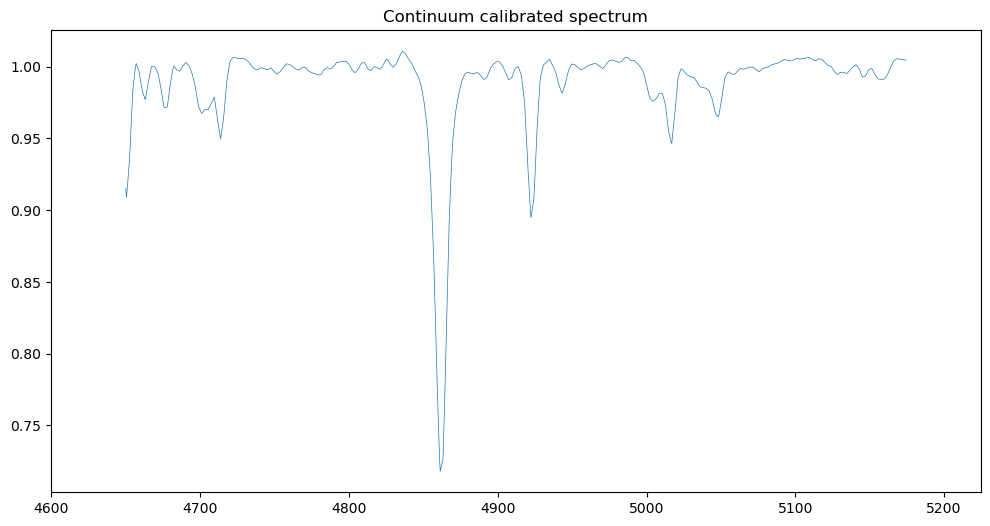

amp = -3.3315115250130662 
mu = 4861.873723946588 
sigma = 3.2130418833342214 
gamma = 1.7921239142805403 
offset = 1.0 
chi2 = 0.0017156710901840974


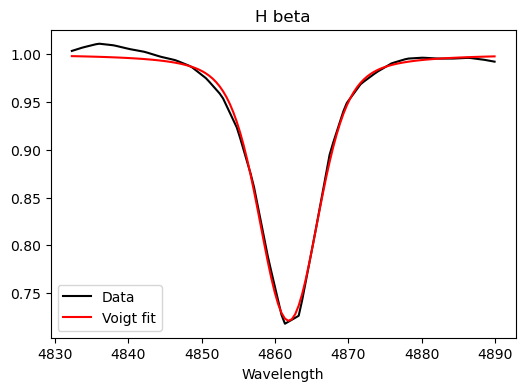

Lambda =  4861.873723946588 Eq Width = 3.3315115250130662 FWHM =  9.663979188236077 Intensity =  -0.27884909207179615


### Measuring He I 4009

#### He I 4009 preliminary fit

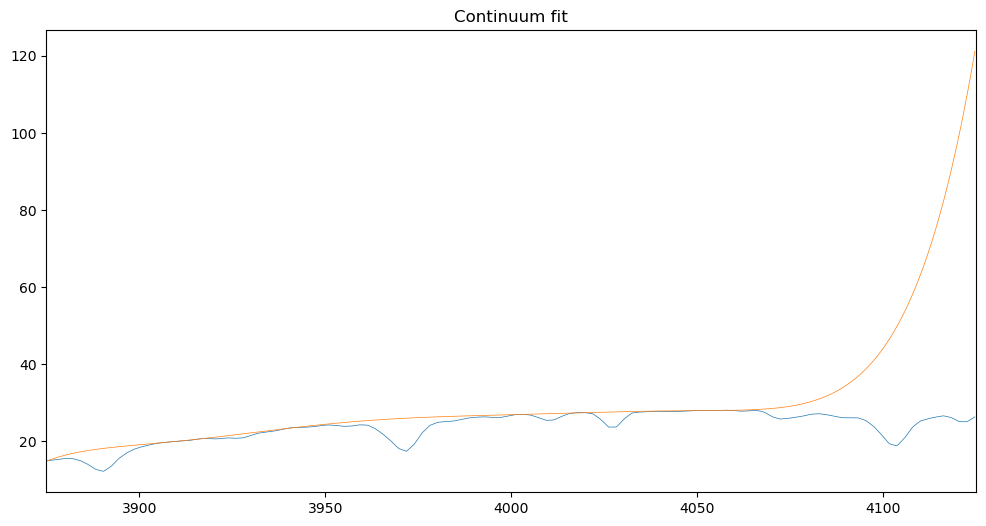

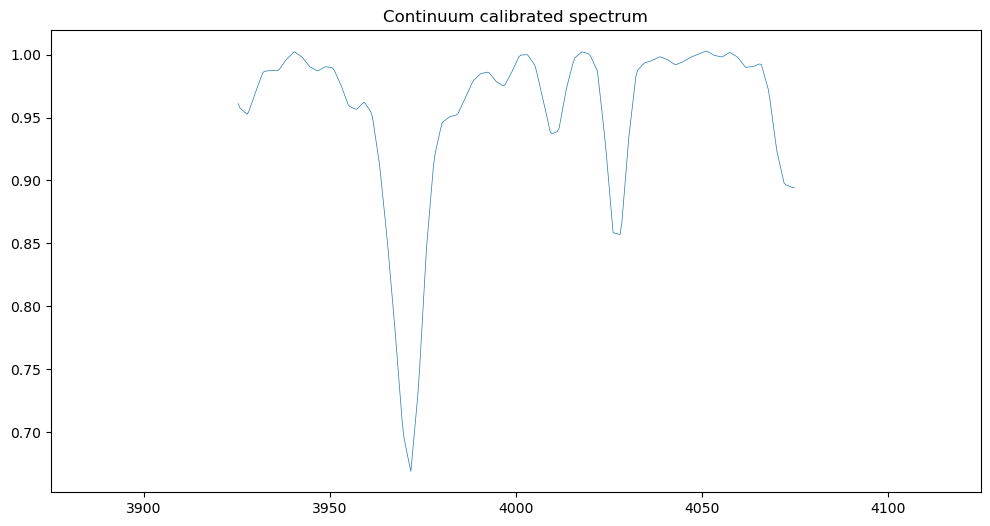

amp = -0.06484778585350588 
mu = 4010.219208322884 
sigma = 2.5835507419143515 
offset = 1.0 
chi2 =  5.1351167156236996e-05


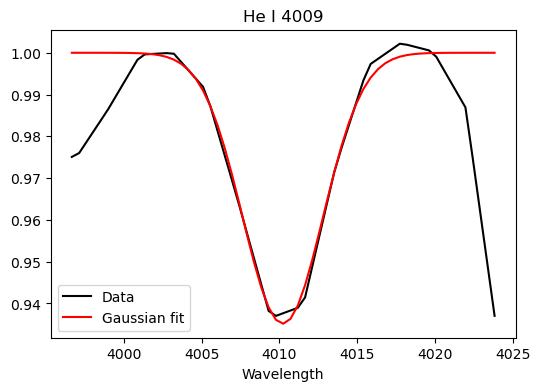

Lambda =  4010.219208322884 Eq Width = 0.41995434799426296 FWHM =  6.084261997208298 Intensity =  -0.06484778585350588


#### He I 4009 optimization

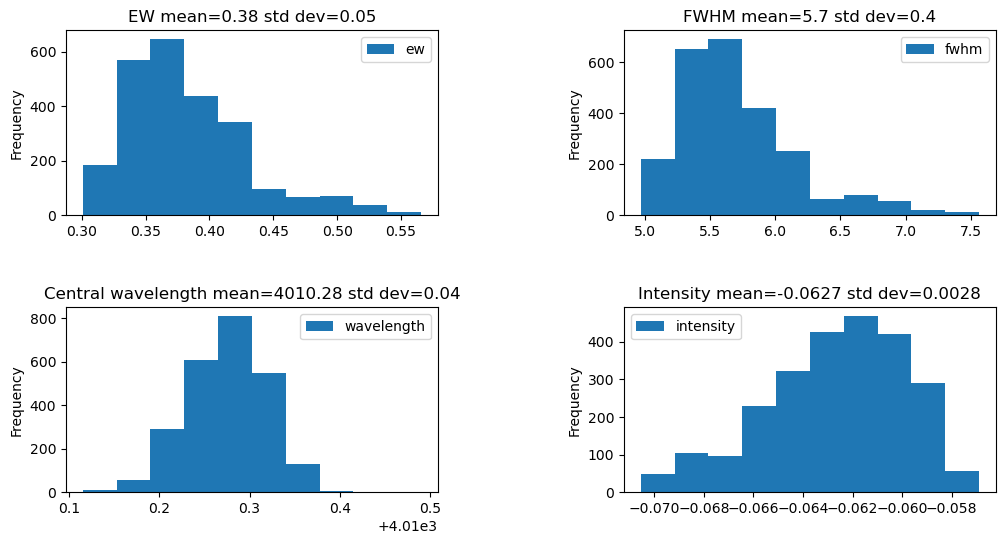

#### He I 4009 re-fit with best parameters

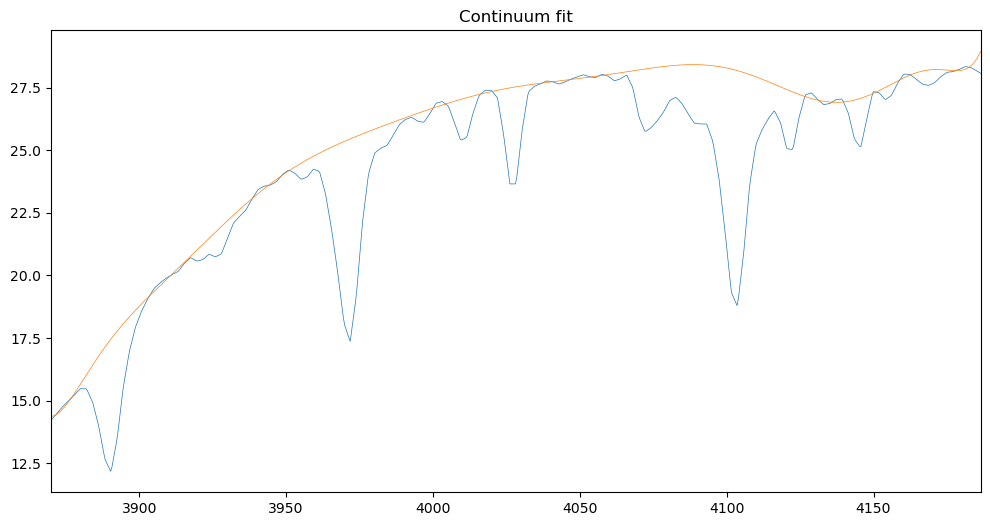

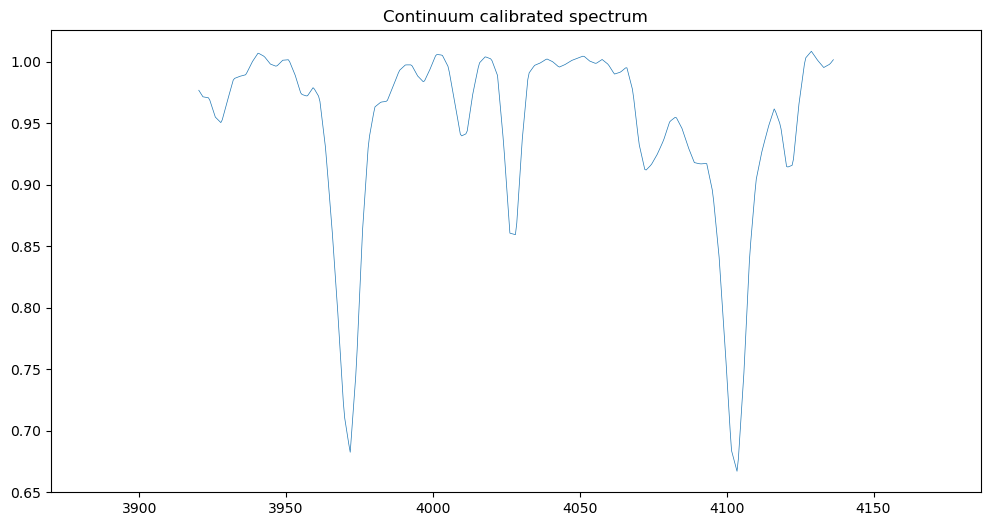

amp = -0.06316915616628054 
mu = 4010.2909092727914 
sigma = 2.4292794813782597 
offset = 1.0 
chi2 =  8.503689450696643e-05


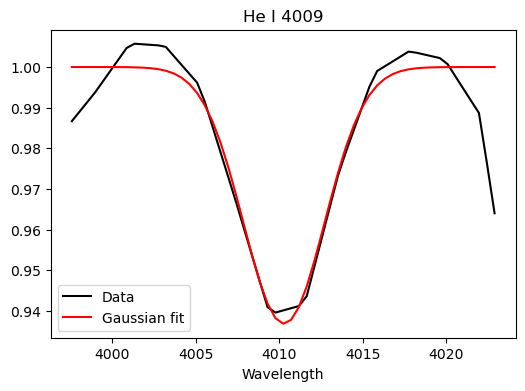

Lambda =  4010.2909092727914 Eq Width = 0.38465598275597856 FWHM =  5.720953178645802 Intensity =  -0.06316915616628054


### Measuring He I 4026

#### He I 4026 preliminary fit

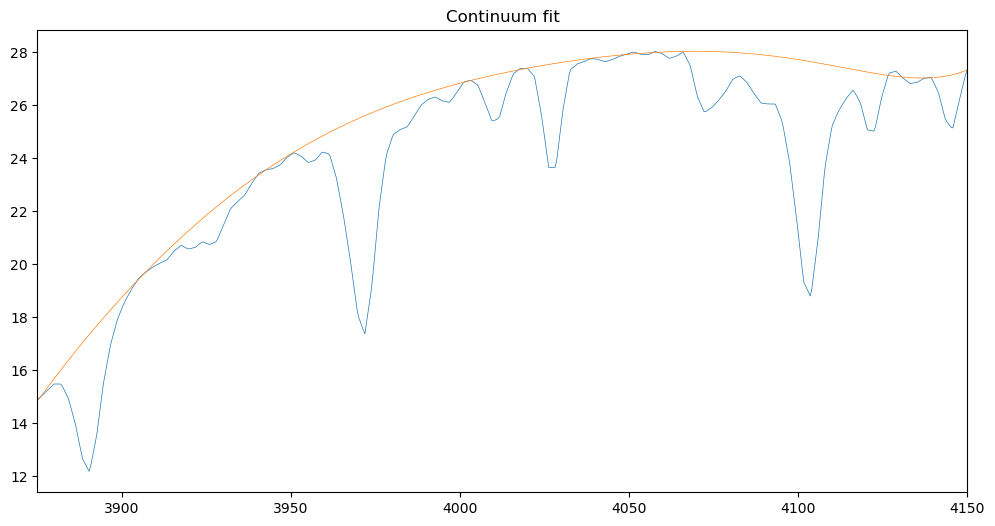

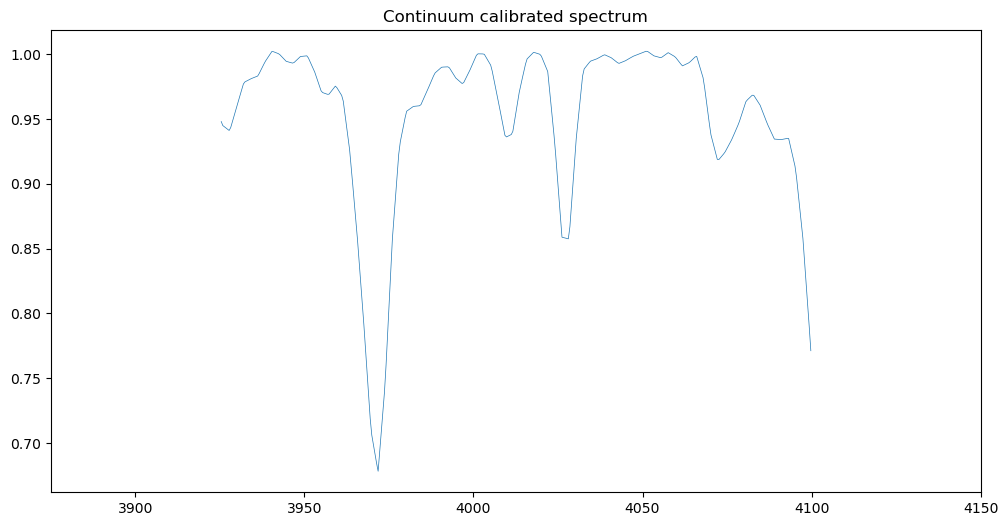

amp = -0.1472872417286292 
mu = 4027.192881399263 
sigma = 2.5493801632063606 
offset = 1.0 
chi2 =  0.00019050574575346215


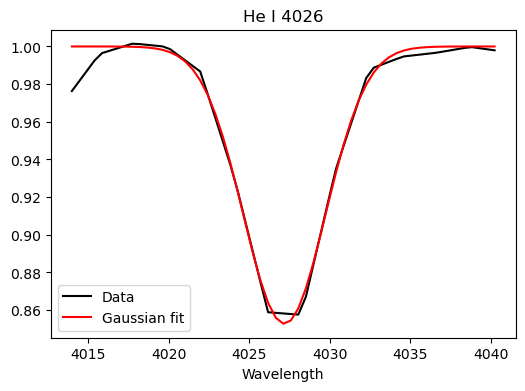

Lambda =  4027.192881399263 Eq Width = 0.9412167895027626 FWHM =  6.00379028435098 Intensity =  -0.1472872417286292


#### He I 4026 optimization

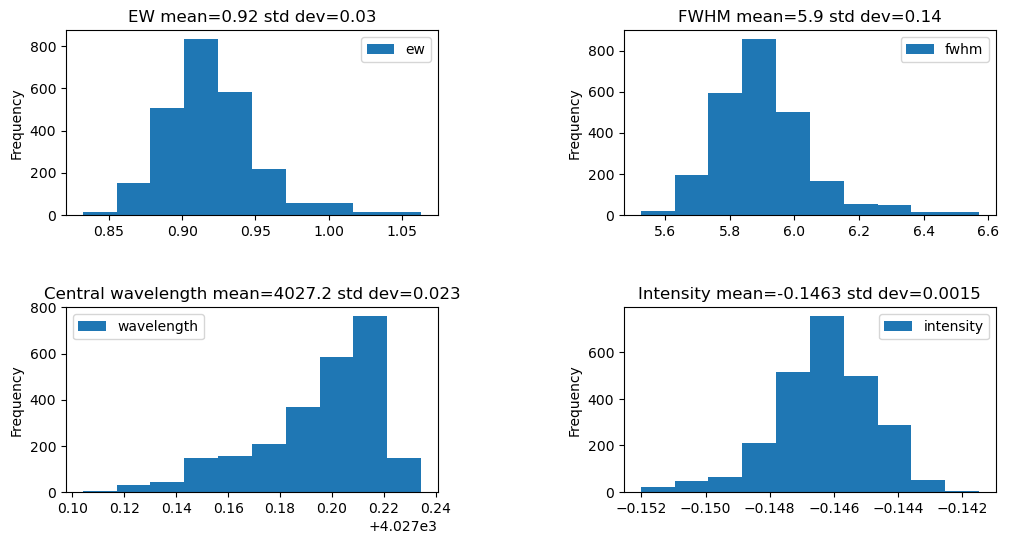

#### He I 4026 re-fit with best parameters

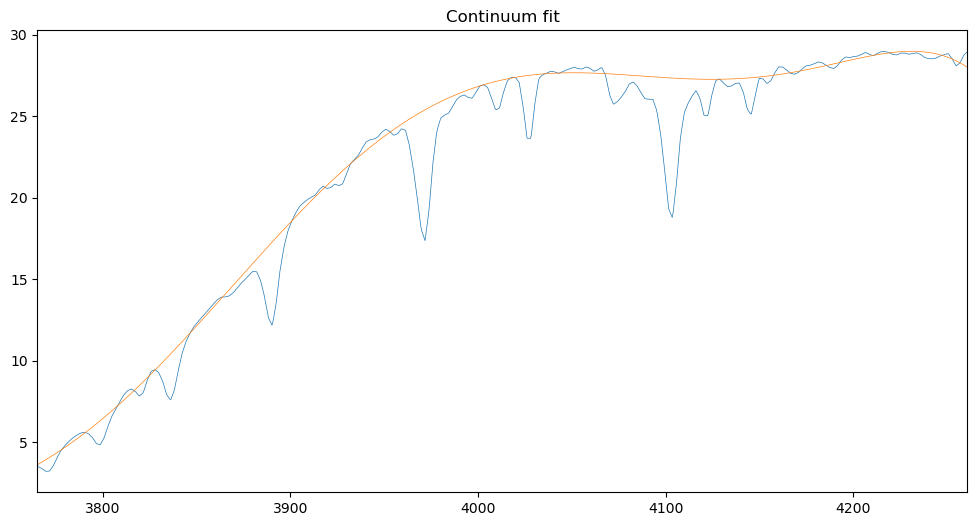

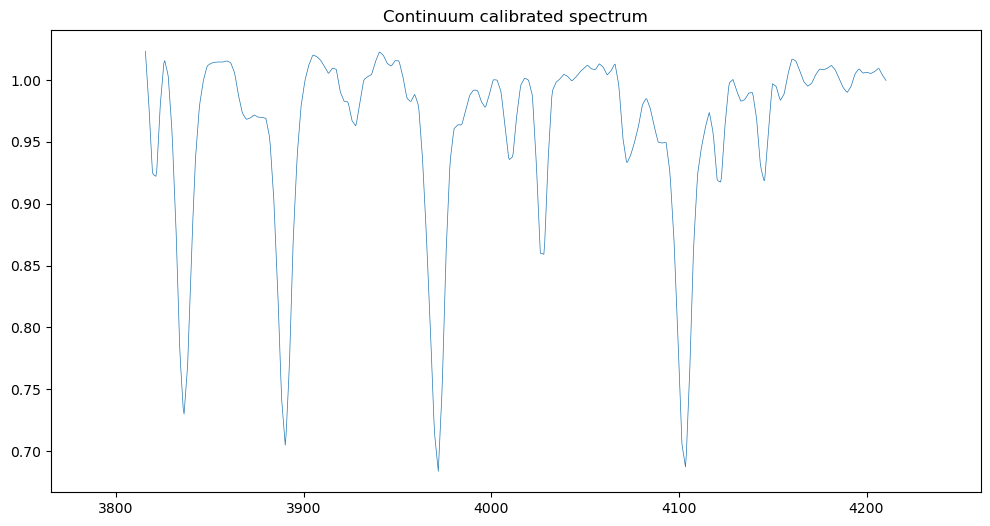

amp = -0.14643068672753567 
mu = 4027.166085879967 
sigma = 2.506822319313264 
offset = 1.0 
chi2 =  0.0002226191919320831


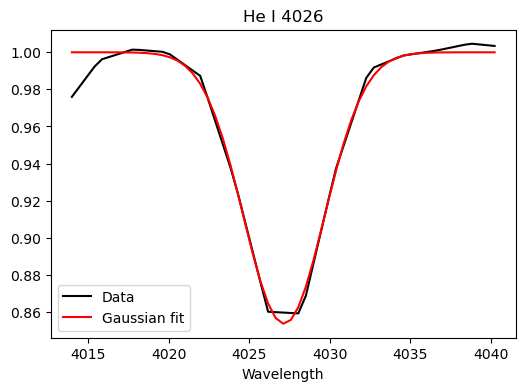

Lambda =  4027.166085879967 Eq Width = 0.9201223629433003 FWHM =  5.903566561982736 Intensity =  -0.14643068672753567


### Measuring He I 4388

#### He I 4388 preliminary fit

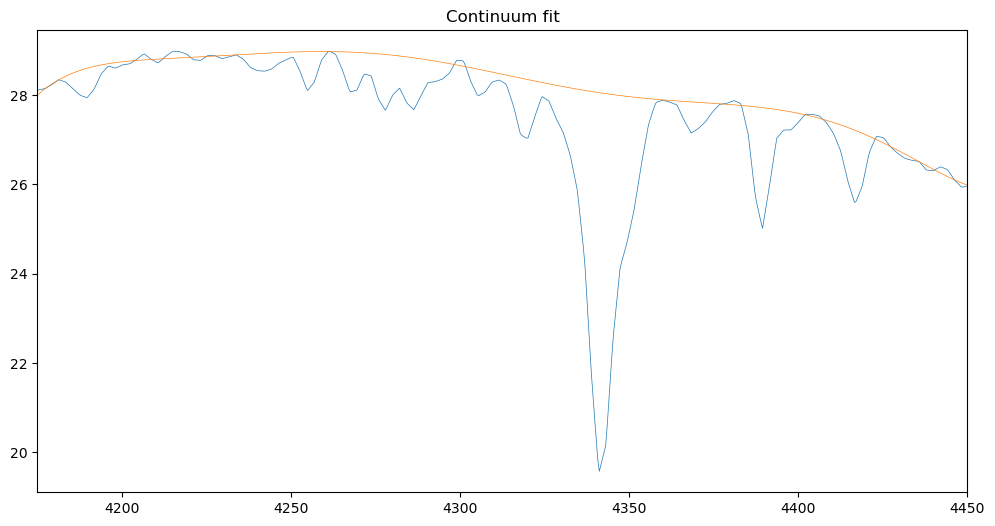

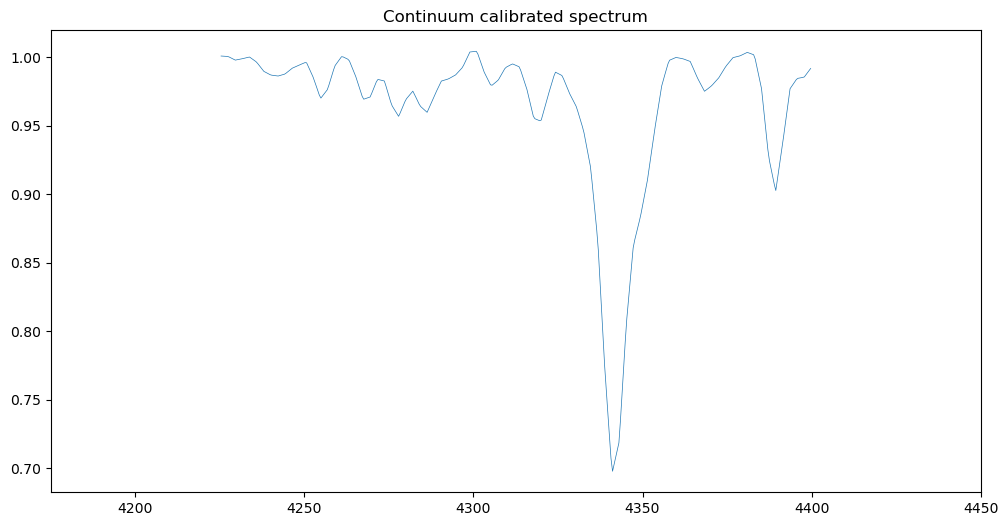

amp = -0.09111479866960291 
mu = 4389.335421583867 
sigma = 2.686321393463696 
offset = 1.0 
chi2 =  0.0004843982962320049


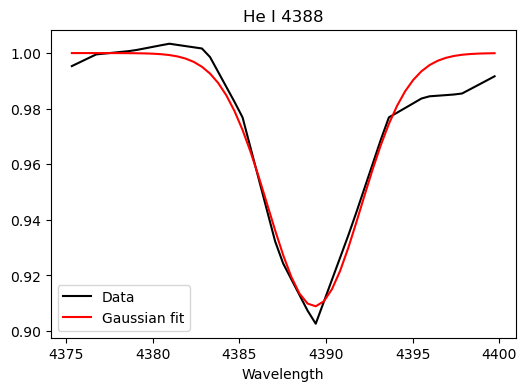

Lambda =  4389.335421583867 Eq Width = 0.6135314428969529 FWHM =  6.326286881607004 Intensity =  -0.09111479866960291


#### He I 4388 optimization

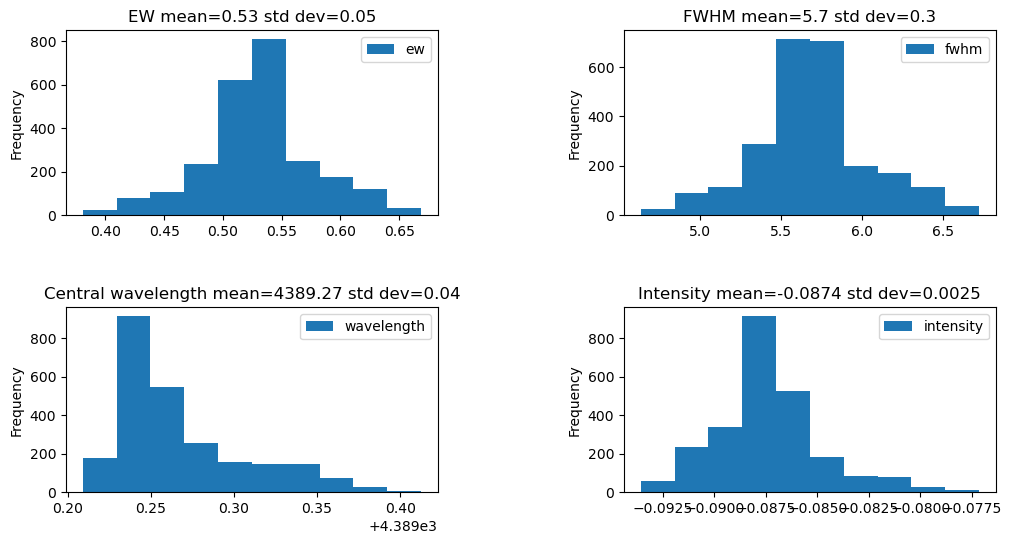

#### He I 4388 re-fit with best parameters

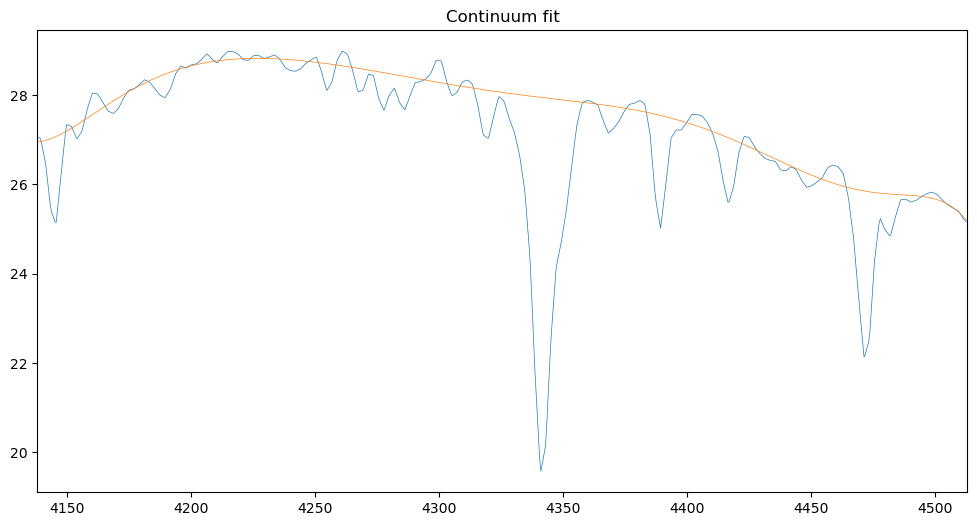

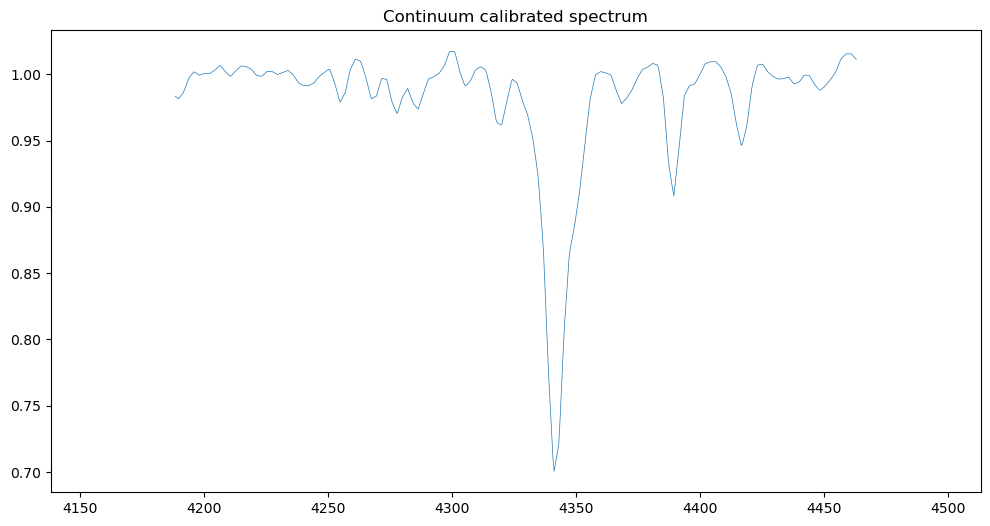

amp = -0.08755830109471646 
mu = 4389.2629984990635 
sigma = 2.4124571812990108 
offset = 1.0 
chi2 =  0.0001990178459814295


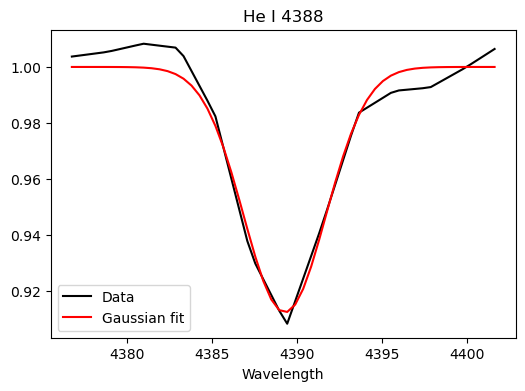

Lambda =  4389.2629984990635 Eq Width = 0.5294767254193776 FWHM =  5.68133666195917 Intensity =  -0.08755830109471646


### Measuring He I 4922

#### He I 4922 preliminary fit

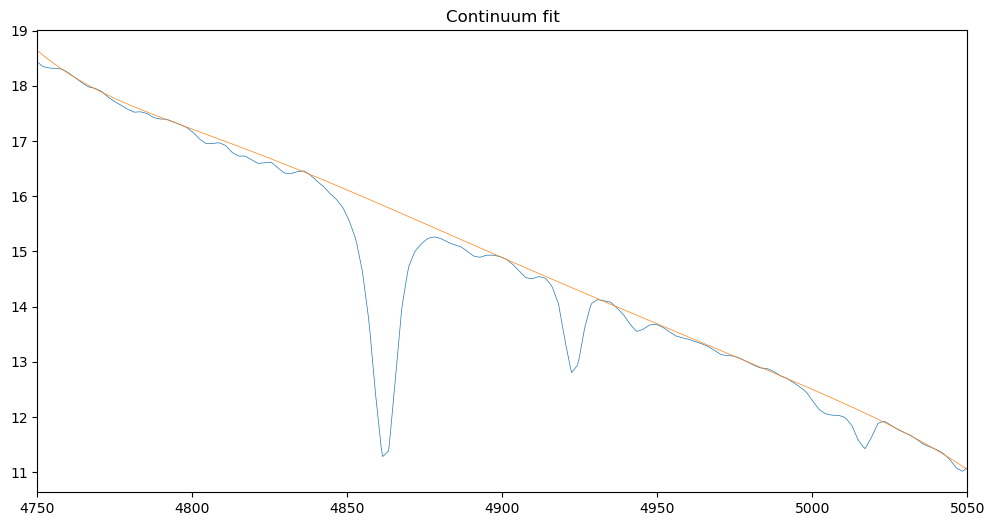

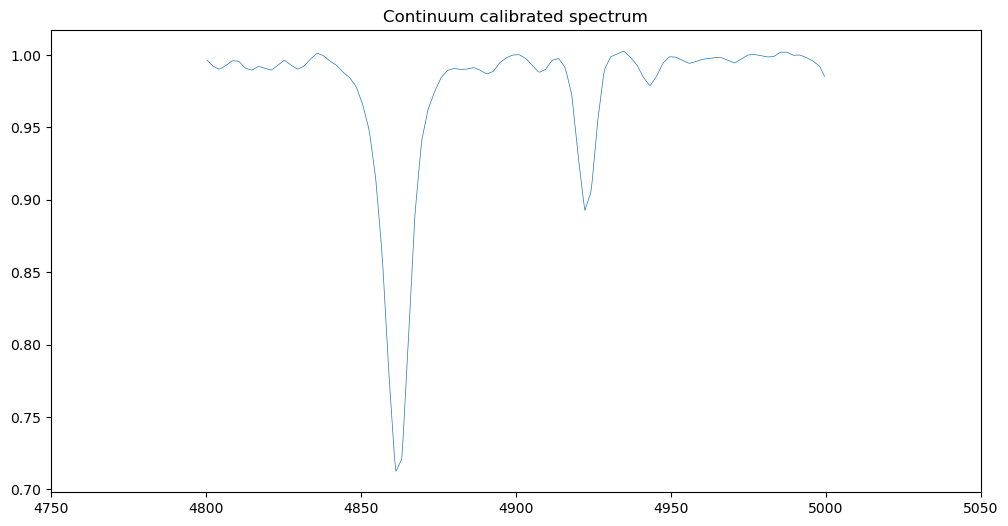

amp = -0.10480158987359146 
mu = 4922.743181430198 
sigma = 2.9174601585459516 
offset = 1.0 
chi2 =  9.770125108668991e-05


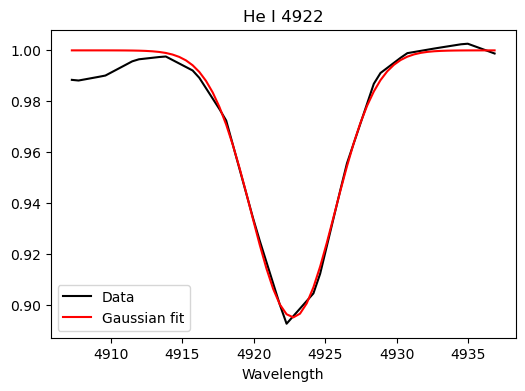

Lambda =  4922.743181430198 Eq Width = 0.7664127820716641 FWHM =  6.870618673375716 Intensity =  -0.10480158987359146


#### He I 4922 optimization

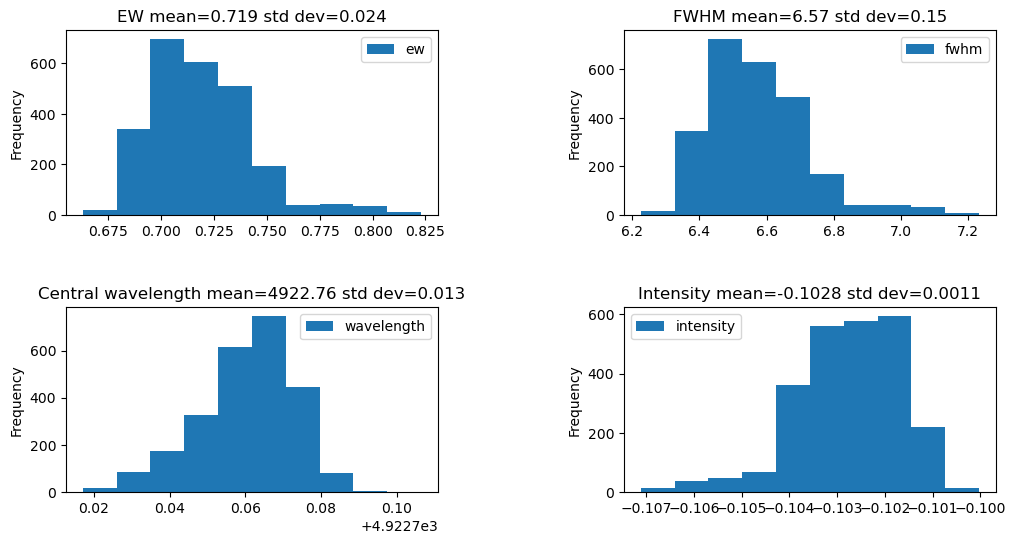

#### He I 4922 re-fit with best parameters

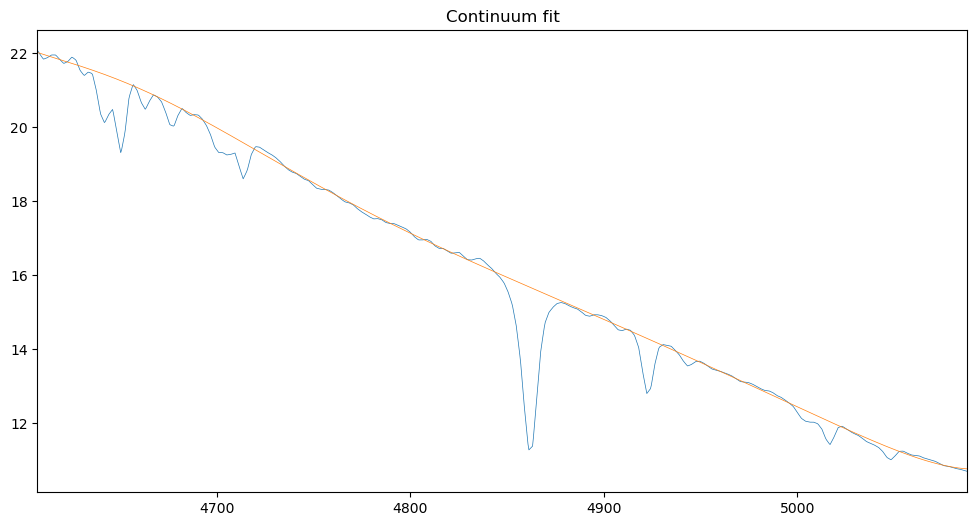

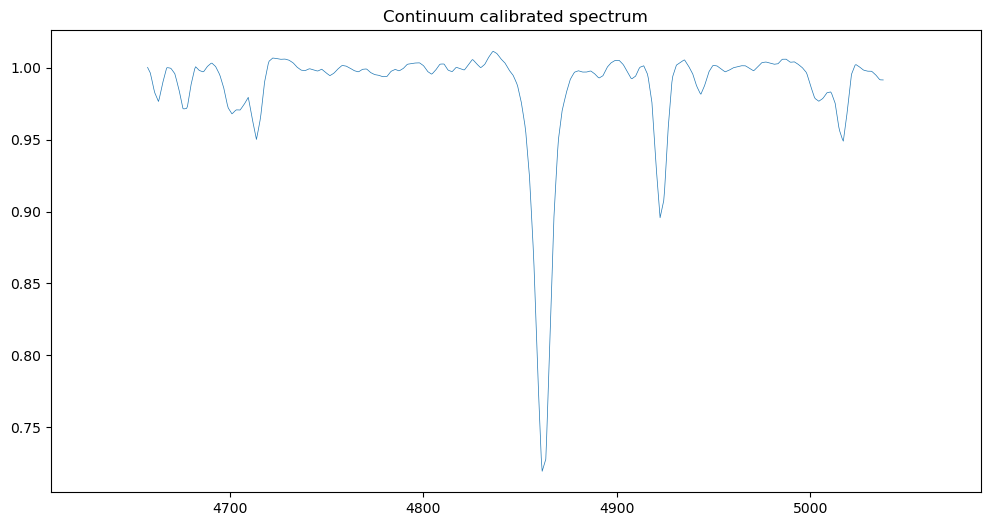

amp = -0.10279009366212037 
mu = 4922.758506139131 
sigma = 2.7883941246401296 
offset = 1.0 
chi2 =  0.0001019494388349728


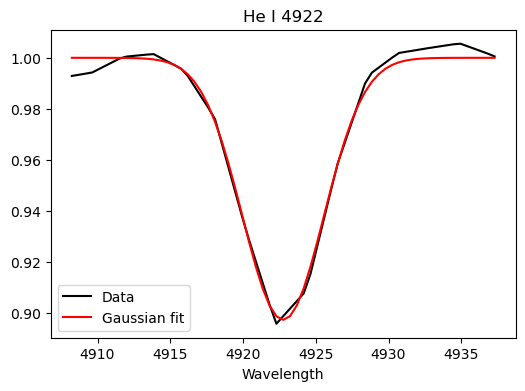

Lambda =  4922.758506139131 Eq Width = 0.7184480244867918 FWHM =  6.566668163527505 Intensity =  -0.10279009366212037


### Measuring He I 6678

#### He I 6678 preliminary fit

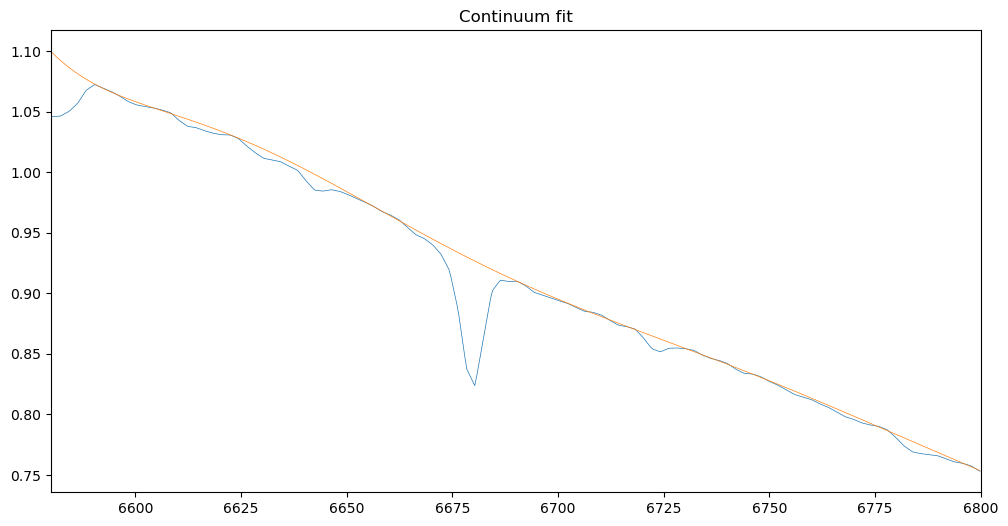

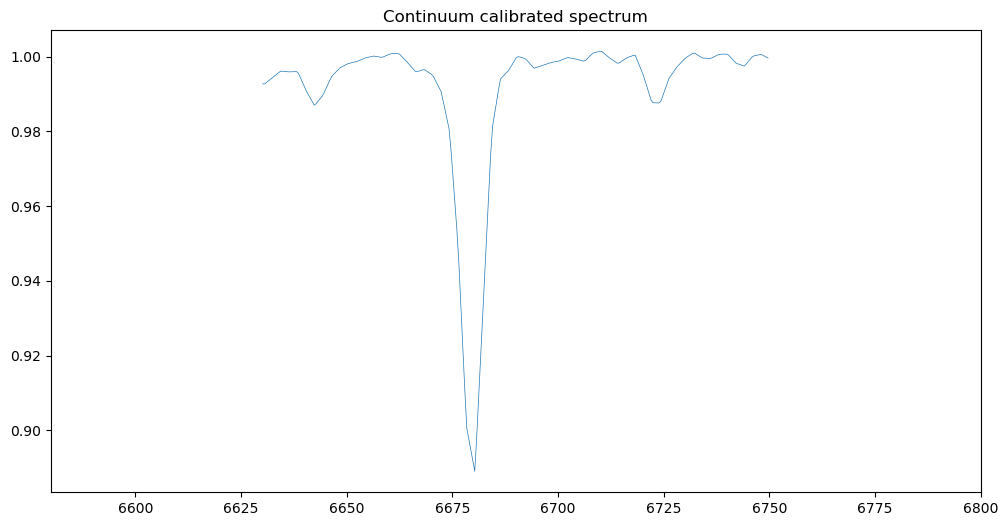

amp = -0.10718240245138227 
mu = 6679.597959899414 
sigma = 2.8041088230832814 
offset = 1.0 
chi2 =  0.00023604878528482197


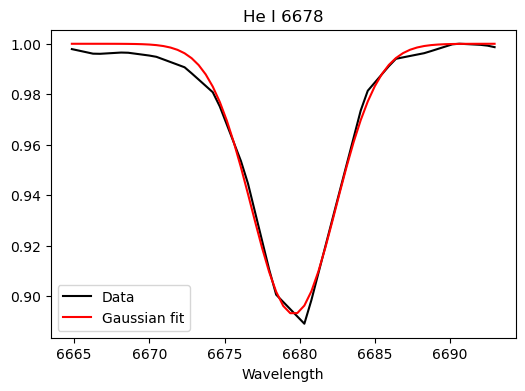

Lambda =  6679.597959899414 Eq Width = 0.7533699363495812 FWHM =  6.603676278361127 Intensity =  -0.10718240245138227


#### He I 6678 optimization

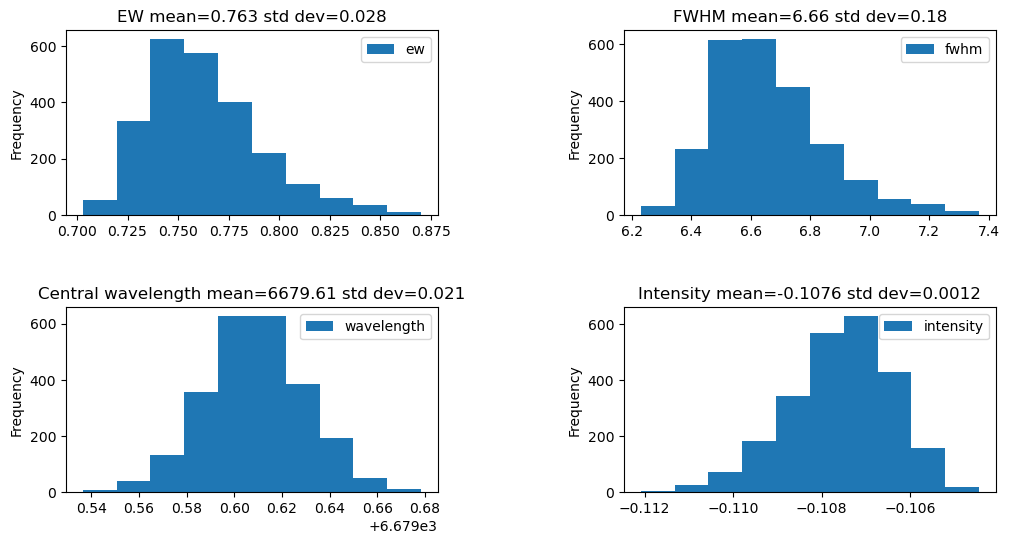

#### He I 6678 re-fit with best parameters

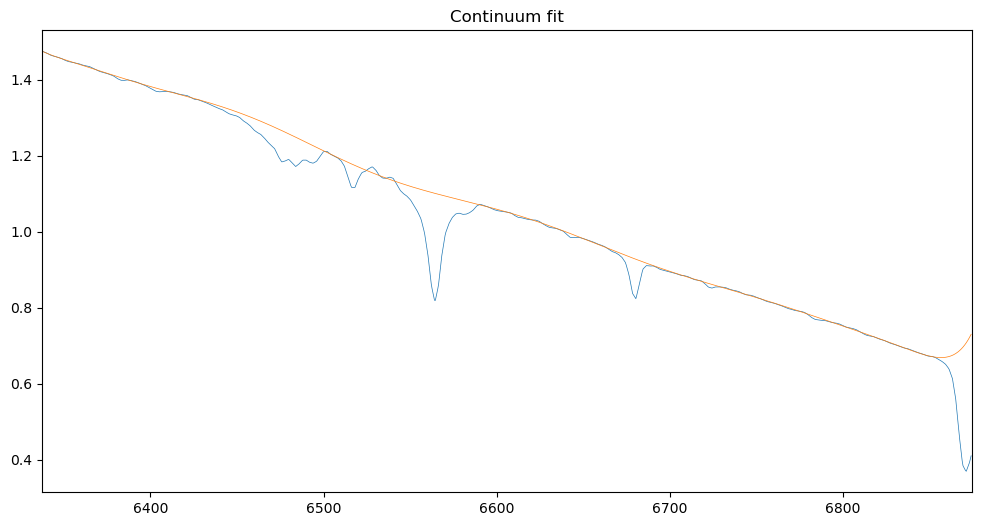

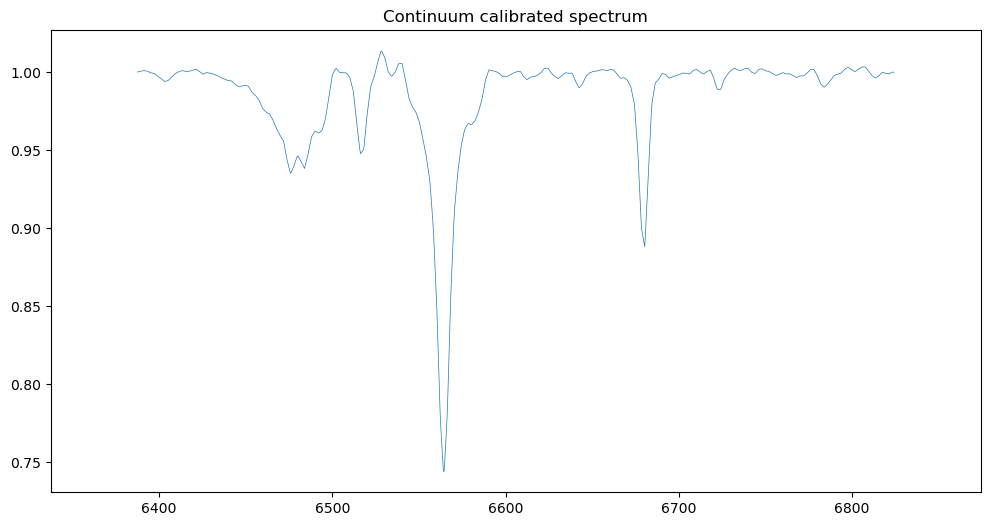

amp = -0.10774768844628041 
mu = 6679.603484122374 
sigma = 2.8395248740987657 
offset = 1.0 
chi2 =  0.0002490772249523084


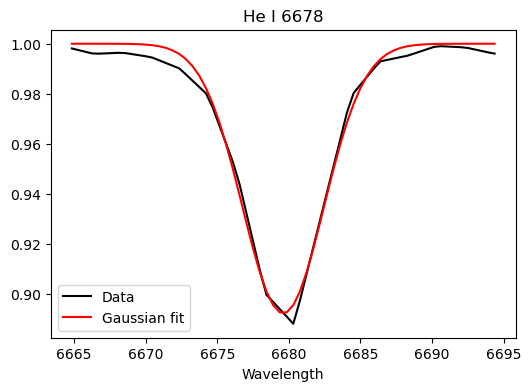

Lambda =  6679.603484122374 Eq Width = 0.7669085391550758 FWHM =  6.687081078502593 Intensity =  -0.10774768844628041


In [29]:
summary_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))

i = 0

for measuring_line in measuring_lines:
    results = measure_line(wl, flux, measuring_line, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results.loc[i] = results
    i = i + 1

## Measure All Blends

### Measuring He I/Mg II 4471-81

Blended lines= [{'name': 'He I 4471', 'wavelength': 4471.0}, {'name': 'Mg II 4481', 'wavelength': 4481.0}, {'name': 'Unknown 4490', 'wavelength': 4490.0}]


#### He I/Mg II 4471-81 preliminary fit

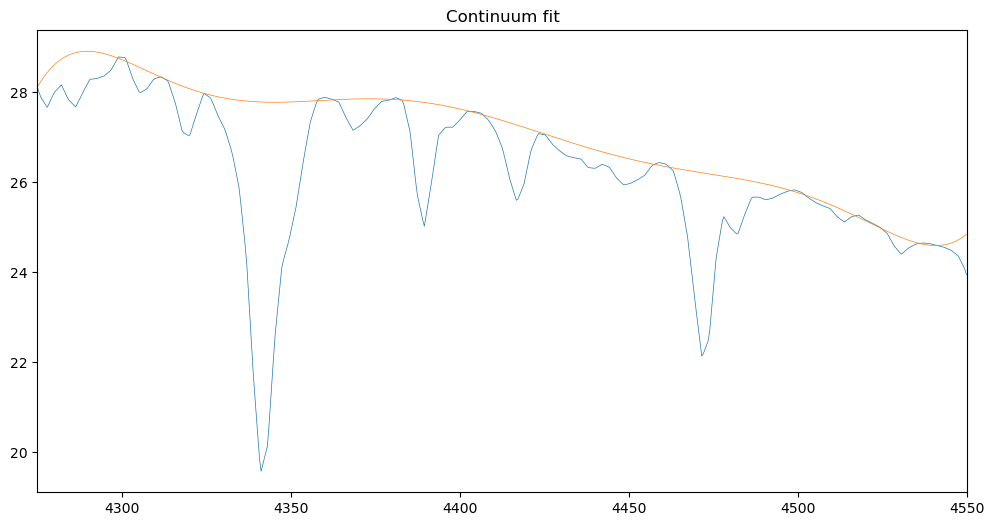

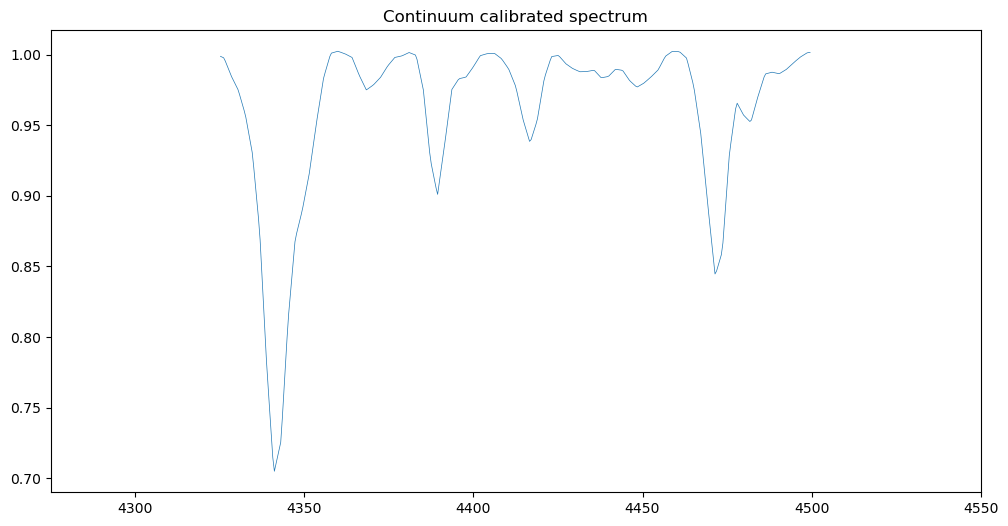

He I 4471 (gauss)
amp = -0.15074612314086464 
mu = 4471.843417232915 
sigma = 3.2639279522910445 
offset = 1.0 
chi2 = 0.0061922740755437165


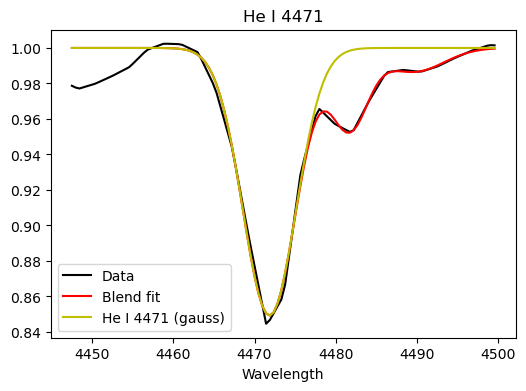

Mg II 4481 (gauss)
amp = -0.044771687251445105 
mu = 4481.651168059453 
sigma = 2.2397159140425345 
offset = 1.0 
chi2 = 0.0061922740755437165


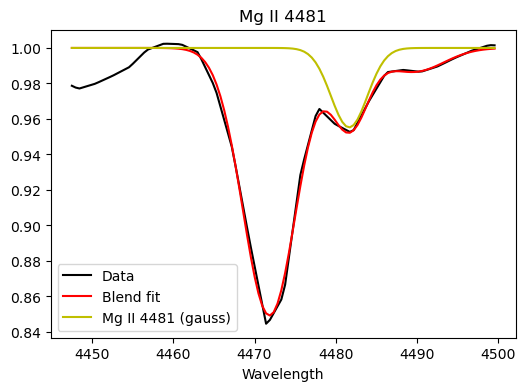

Unknown 4490 (gauss)
amp = -0.013485001397189493 
mu = 4489.548194877118 
sigma = 3.7353038347236422 
offset = 1.0 
chi2 = 0.0061922740755437165


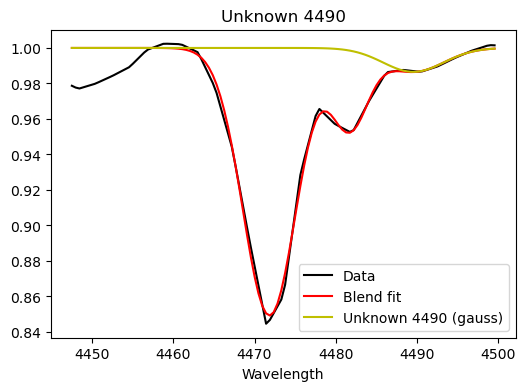

#### He I/Mg II 4471-81 optimization

#### Plotting results for He I 4471

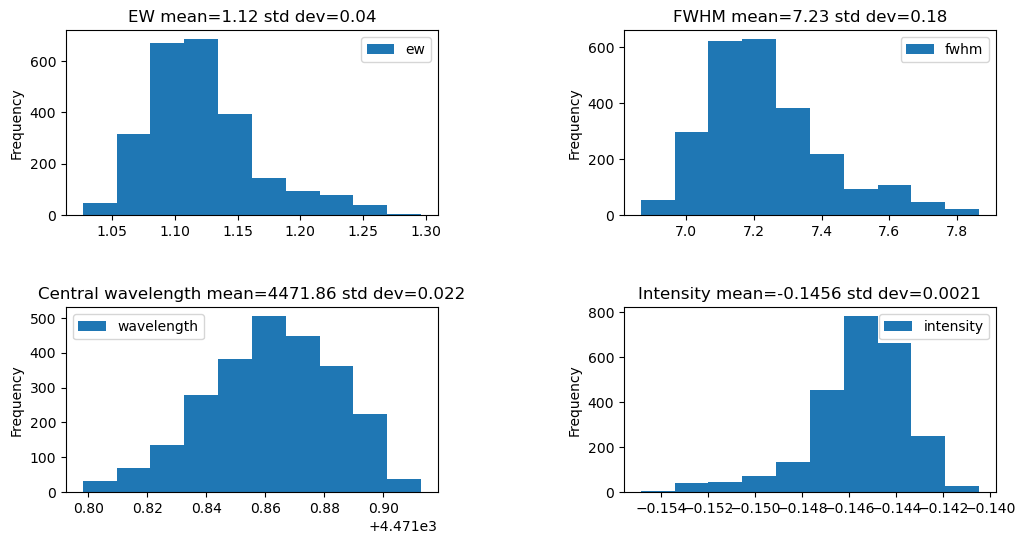

#### Plotting results for Mg II 4481

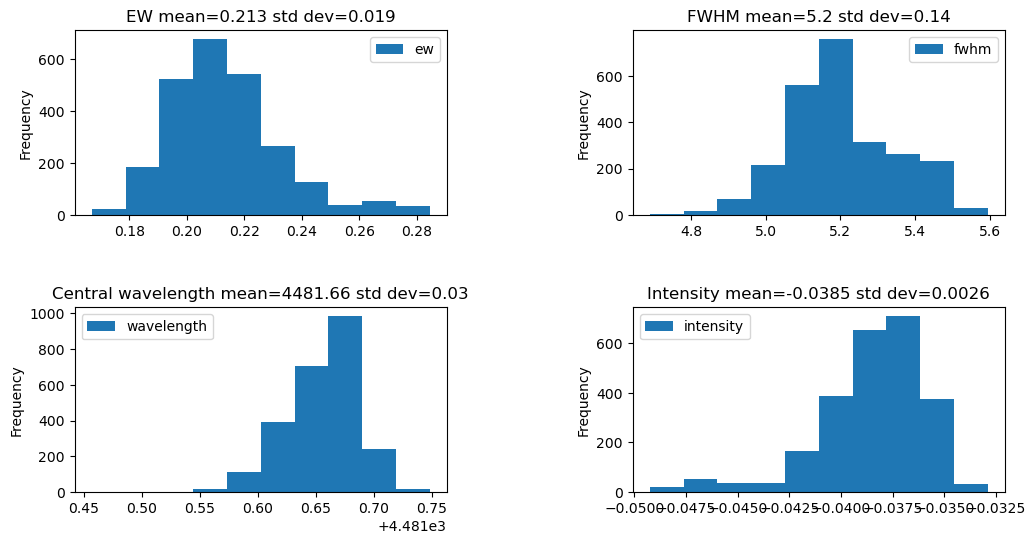

#### Plotting results for Unknown 4490

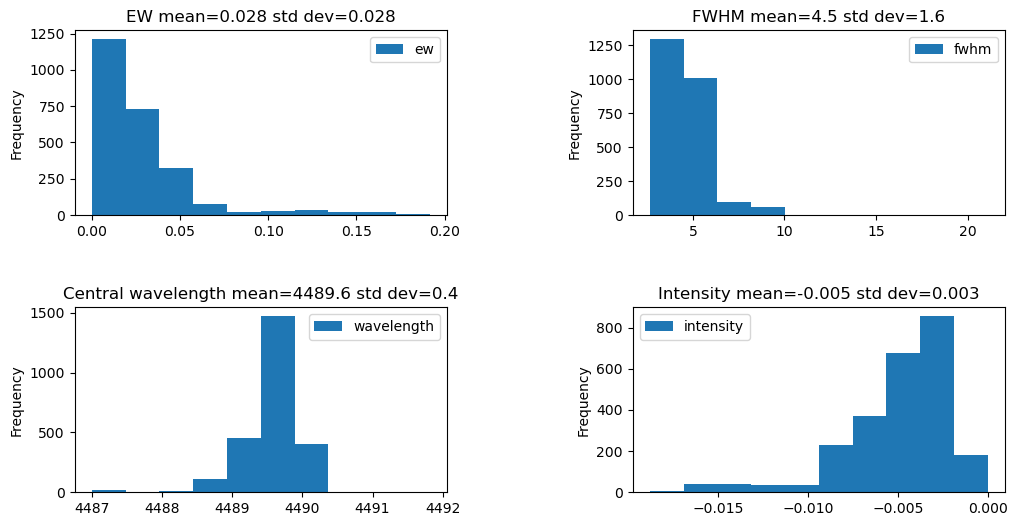

#### He I/Mg II 4471-81 re-fit with best parameters

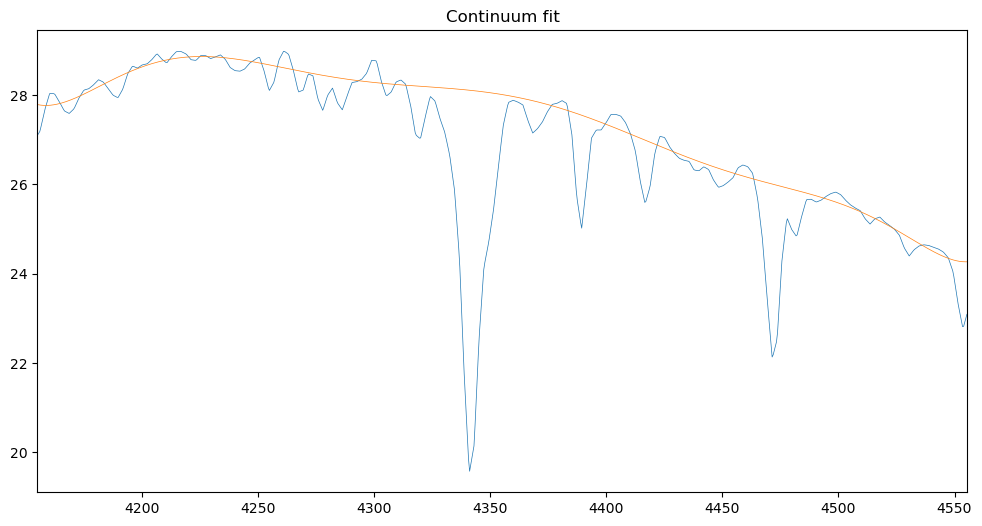

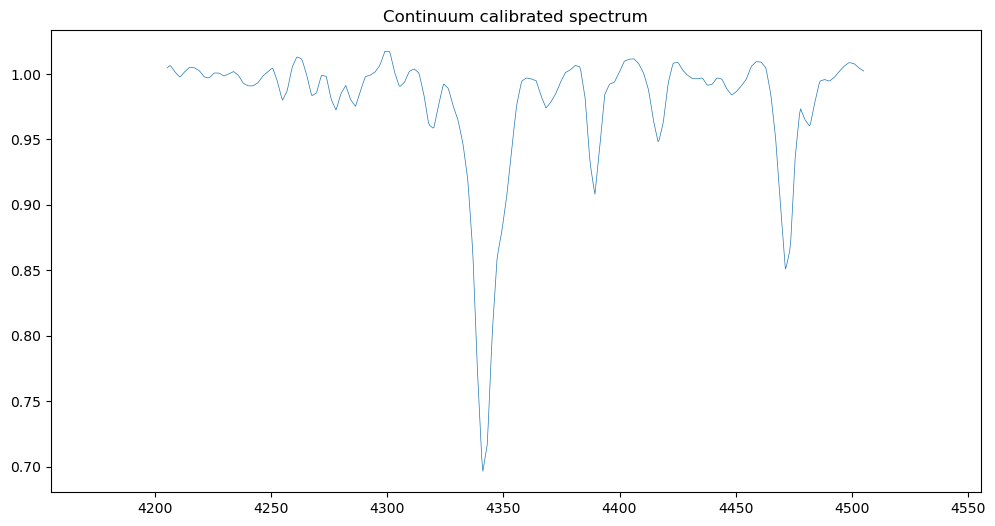

He I 4471 (gauss)
amp = -0.14572729896586542 
mu = 4471.860698099418 
sigma = 3.0753070334283463 
offset = 1.0 
chi2 = 0.004521723815572664


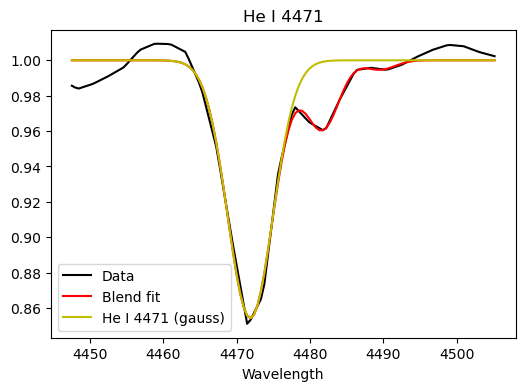

Mg II 4481 (gauss)
amp = -0.038743974032394476 
mu = 4481.6753087324605 
sigma = 2.231373846900899 
offset = 1.0 
chi2 = 0.004521723815572664


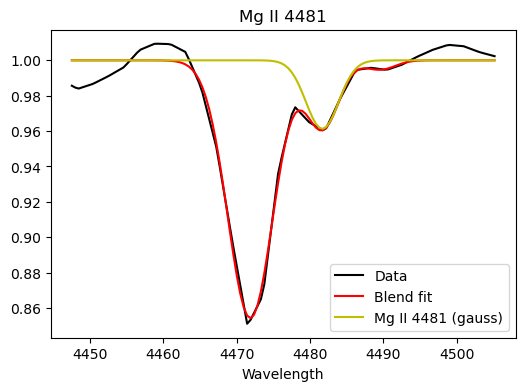

Unknown 4490 (gauss)
amp = -0.005286163890636565 
mu = 4489.547567727712 
sigma = 2.0488080414023244 
offset = 1.0 
chi2 = 0.004521723815572664


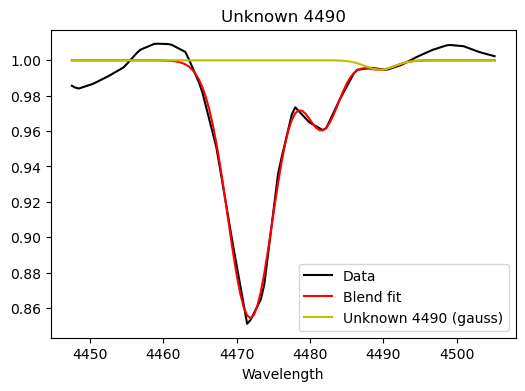

### Measuring He I 4713

Blended lines= [{'name': 'O II 4699', 'wavelength': 4699.0}, {'name': 'O II 4705', 'wavelength': 4705.0}, {'name': 'He I 4713', 'wavelength': 4713.0}]


#### He I 4713 preliminary fit

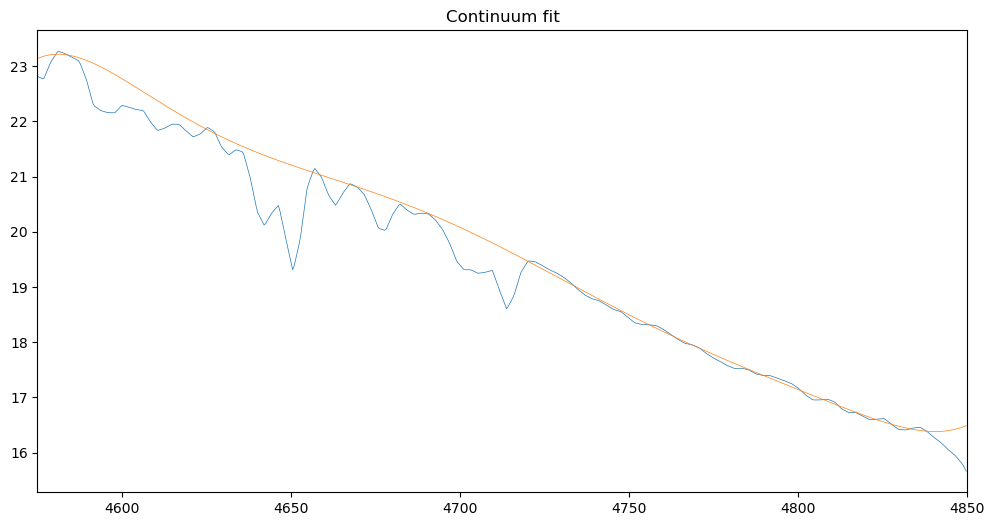

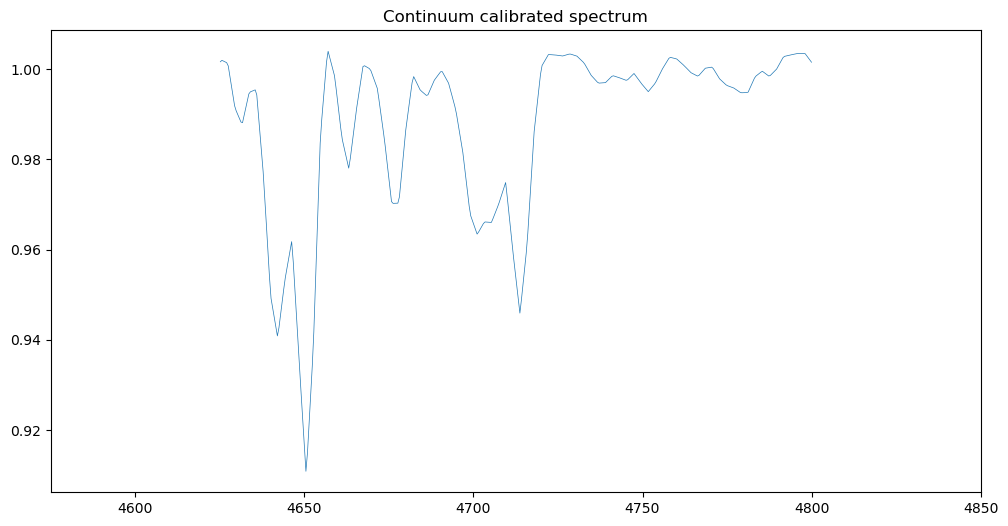

O II 4699 (gauss)
amp = -0.03494695723307357 
mu = 4700.928111478697 
sigma = 3.770941834156066 
offset = 1.0 
chi2 = 0.0005196312791833553


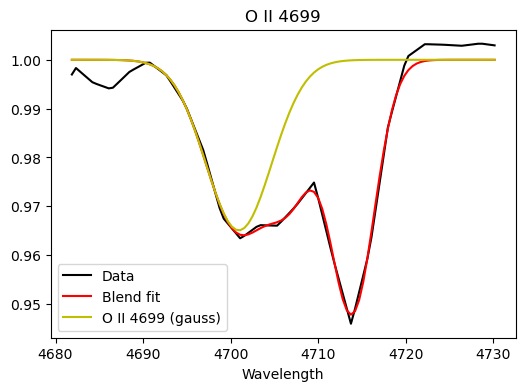

O II 4705 (gauss)
amp = -0.02000491611057815 
mu = 4707.091851534582 
sigma = 2.4279368609476206 
offset = 1.0 
chi2 = 0.0005196312791833553


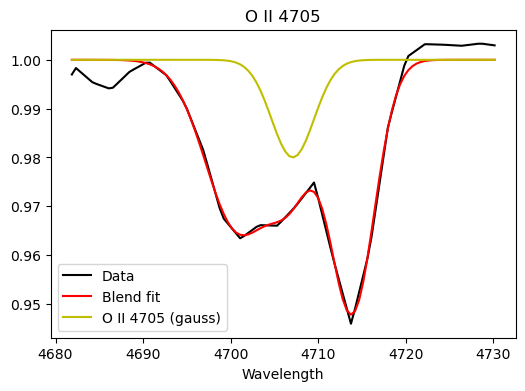

He I 4713 (gauss)
amp = -0.05167885464199995 
mu = 4713.838066605259 
sigma = 2.5504131206232485 
offset = 1.0 
chi2 = 0.0005196312791833553


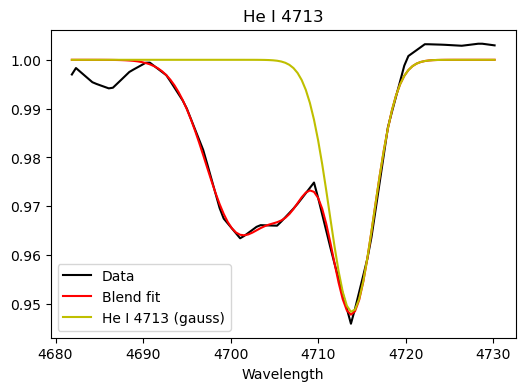

#### He I 4713 optimization

#### Plotting results for O II 4699

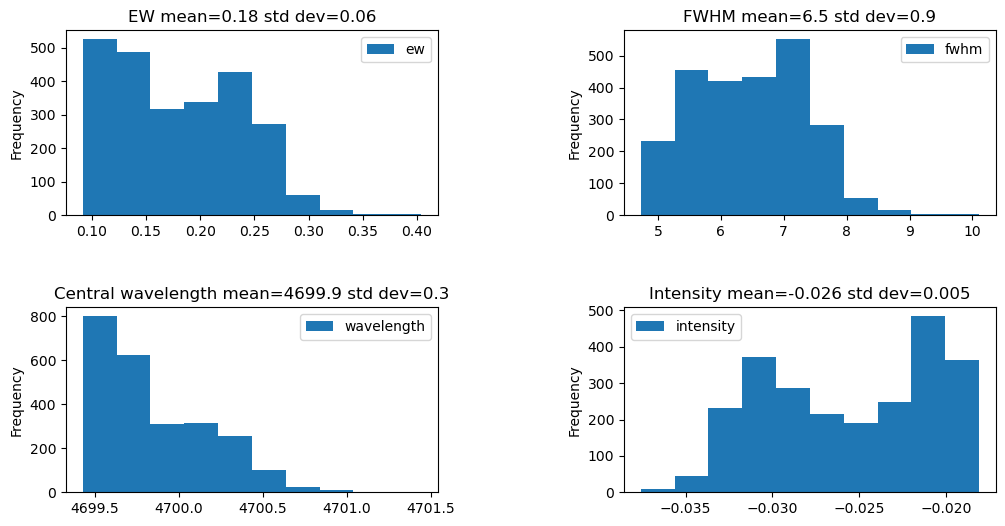

#### Plotting results for O II 4705

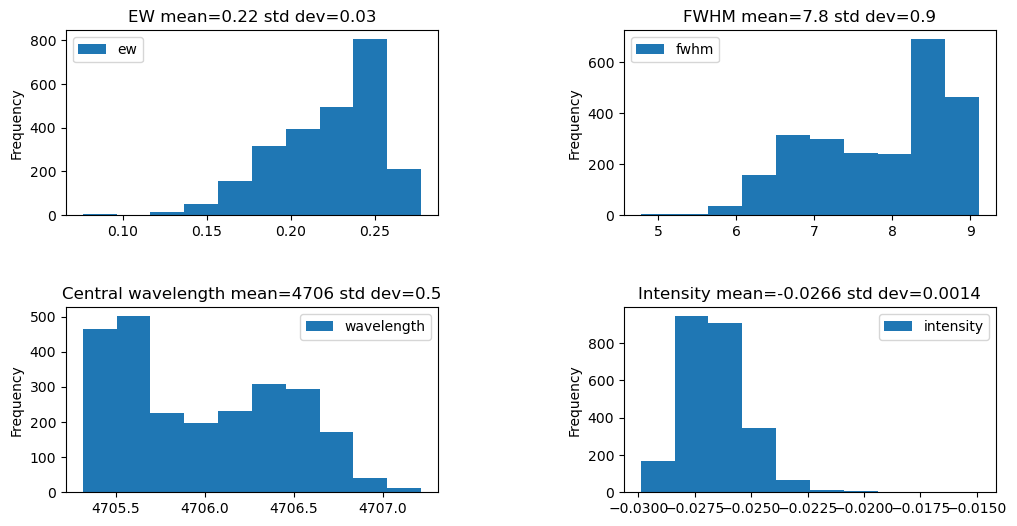

#### Plotting results for He I 4713

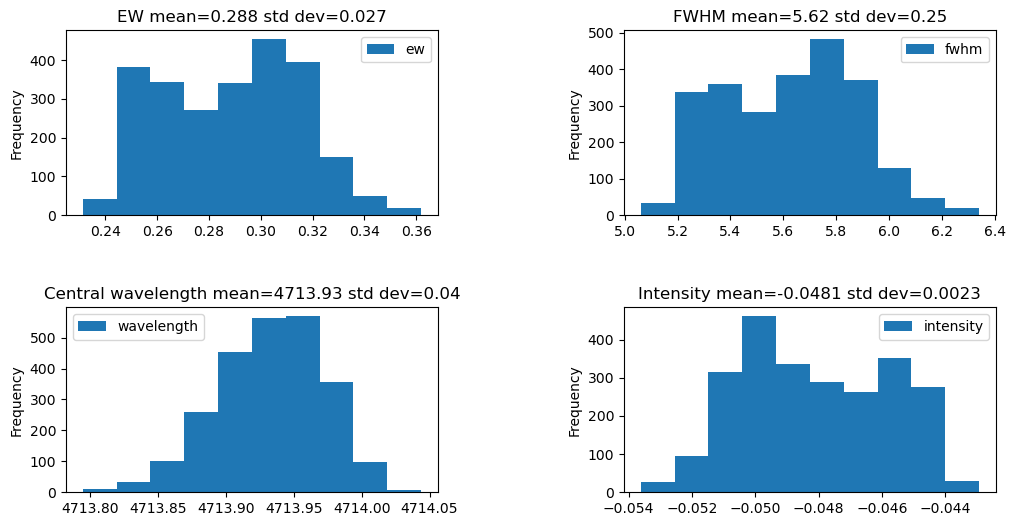

#### He I 4713 re-fit with best parameters

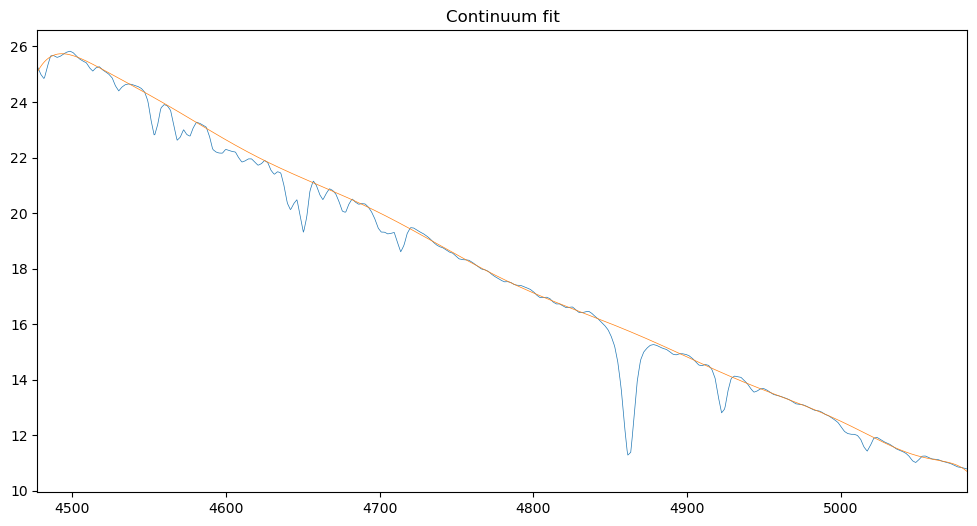

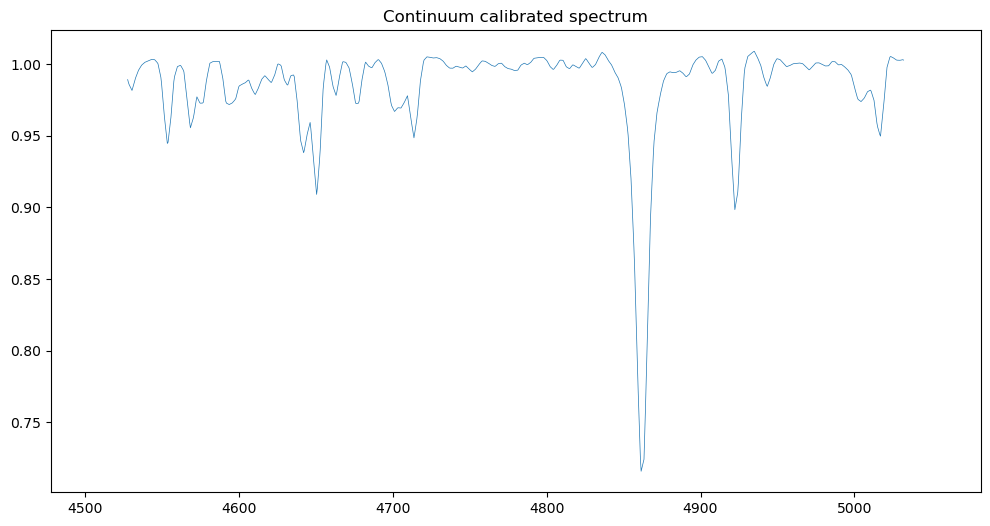

O II 4699 (gauss)
amp = -0.023473422321471996 
mu = 4699.5769796714785 
sigma = 2.6581917583721686 
offset = 1.0 
chi2 = 0.0005711167477413577


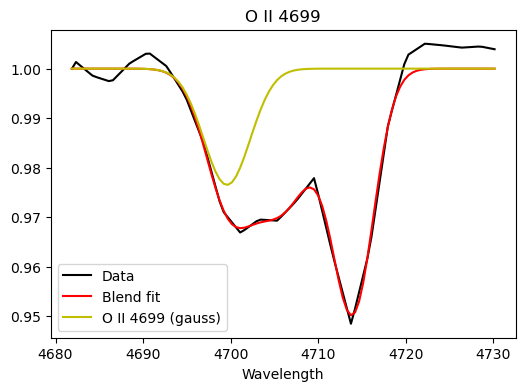

O II 4705 (gauss)
amp = -0.028009878335540906 
mu = 4705.750486726157 
sigma = 3.620751136952236 
offset = 1.0 
chi2 = 0.0005711167477413577


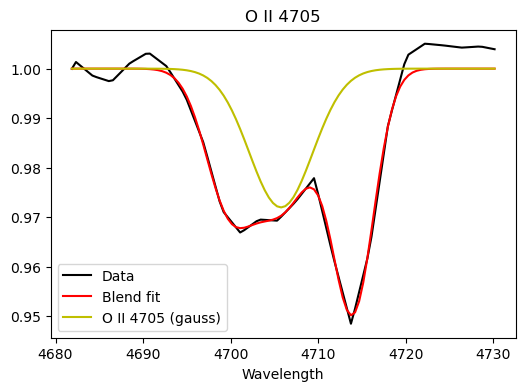

He I 4713 (gauss)
amp = -0.04757142116059625 
mu = 4713.979032196269 
sigma = 2.3663489742821886 
offset = 1.0 
chi2 = 0.0005711167477413577


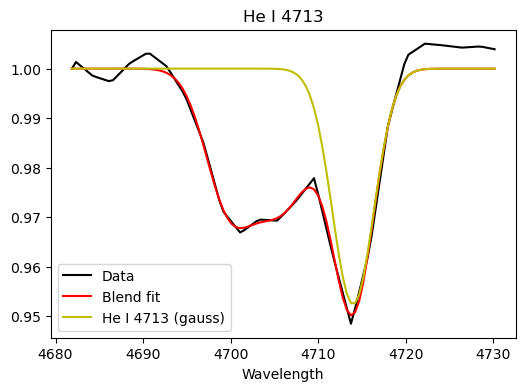

### Measuring H delta / He I 4121-4144

Blended lines= [{'name': 'O II 4072', 'wavelength': 4072.0}, {'name': 'O II 4076', 'wavelength': 4076.0}, {'name': 'O II 4089', 'wavelength': 4089.0}, {'name': 'H delta', 'wavelength': 4101.0, 'model': 'voigt'}, {'name': 'He I 4121', 'wavelength': 4121.0}, {'name': 'O II 4133', 'wavelength': 4133.0}, {'name': 'He I 4144', 'wavelength': 4144.0}, {'name': 'Unknown 4153', 'wavelength': 4153.0}]


#### H delta / He I 4121-4144 preliminary fit

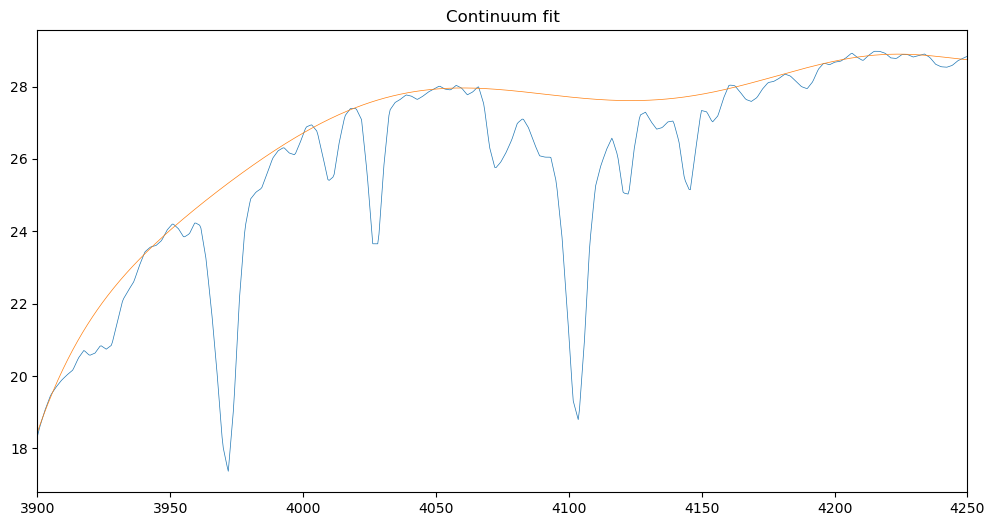

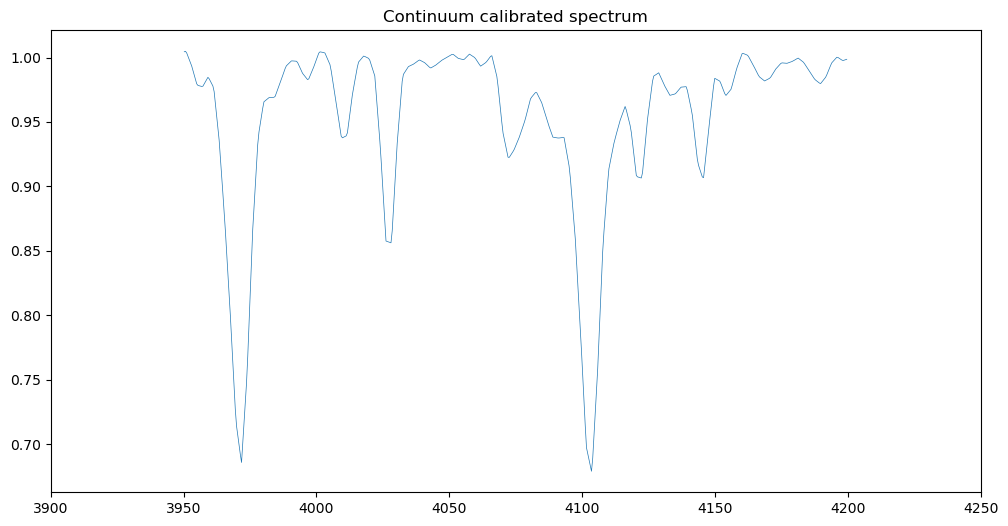

O II 4072 (gauss)
amp = -0.04610942382391854 
mu = 4071.4891310446815 
sigma = 1.9826595313391842 
offset = 1.0 
chi2 = 1.0773483911123138


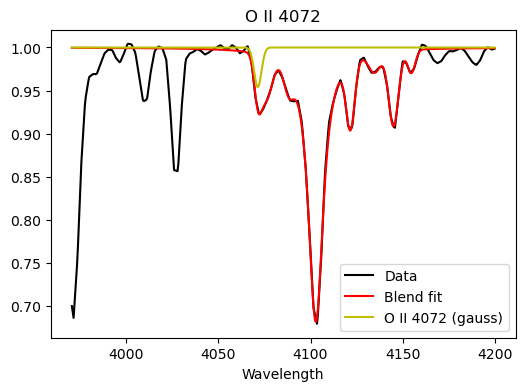

O II 4076 (gauss)
amp = -0.05058432621520565 
mu = 4075.9057112348087 
sigma = 3.3264546140994216 
offset = 1.0 
chi2 = 1.0773483911123138


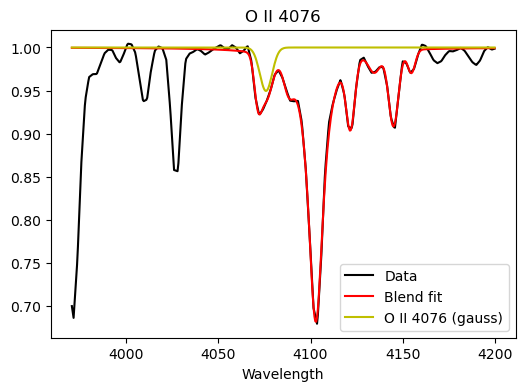

O II 4089 (gauss)
amp = -0.028594920711684506 
mu = 4088.1704775590497 
sigma = 2.685540156449741 
offset = 1.0 
chi2 = 1.0773483911123138


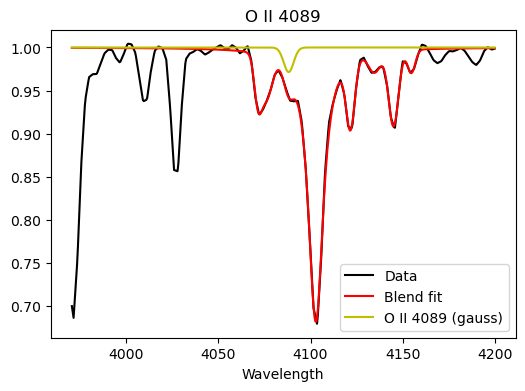

H delta (voigt)
amp = -4.78879993589526 
mu = 4102.856413671013 
sigma = 1.0243536905208268 
gamma = 4.563146060440564 
offset = 1.0 
chi2 = 1.0773483911123138


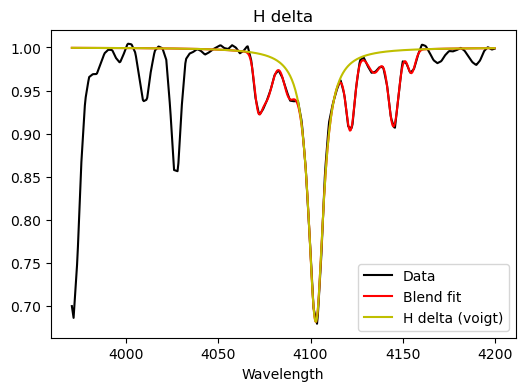

He I 4121 (gauss)
amp = -0.07785162040722152 
mu = 4121.598746834692 
sigma = 2.3269702664968936 
offset = 1.0 
chi2 = 1.0773483911123138


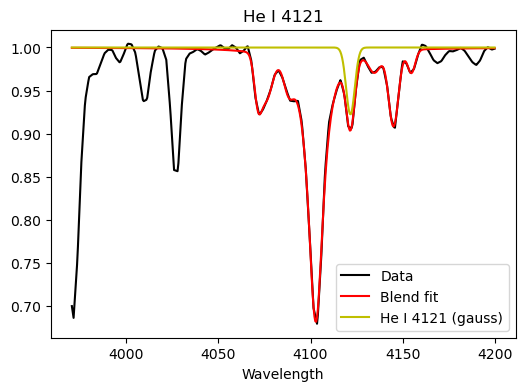

O II 4133 (gauss)
amp = -0.02269230780413536 
mu = 4134.68471028944 
sigma = 3.2151844508357246 
offset = 1.0 
chi2 = 1.0773483911123138


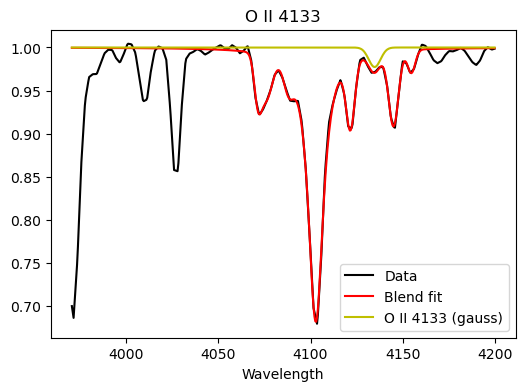

He I 4144 (gauss)
amp = -0.08788801132686185 
mu = 4144.902959740855 
sigma = 2.675295593969821 
offset = 1.0 
chi2 = 1.0773483911123138


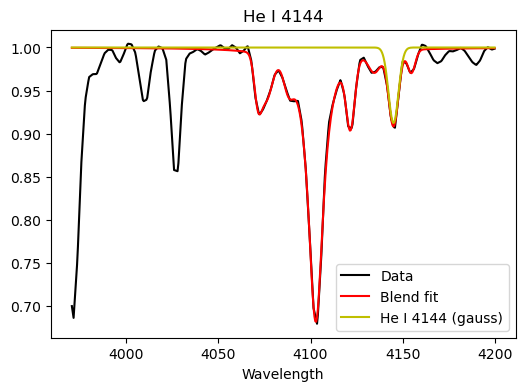

Unknown 4153 (gauss)
amp = -0.027169981929674104 
mu = 4154.54493701437 
sigma = 2.0757090651850887 
offset = 1.0 
chi2 = 1.0773483911123138


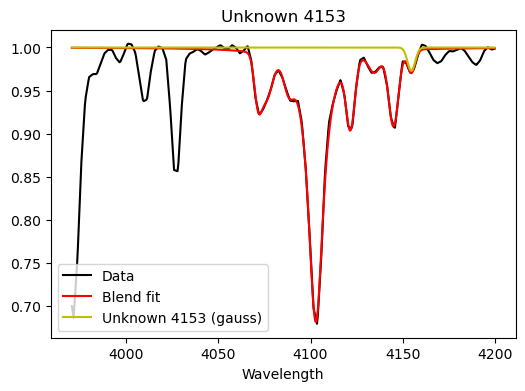

#### H delta / He I 4121-4144 optimization

#### Plotting results for O II 4072

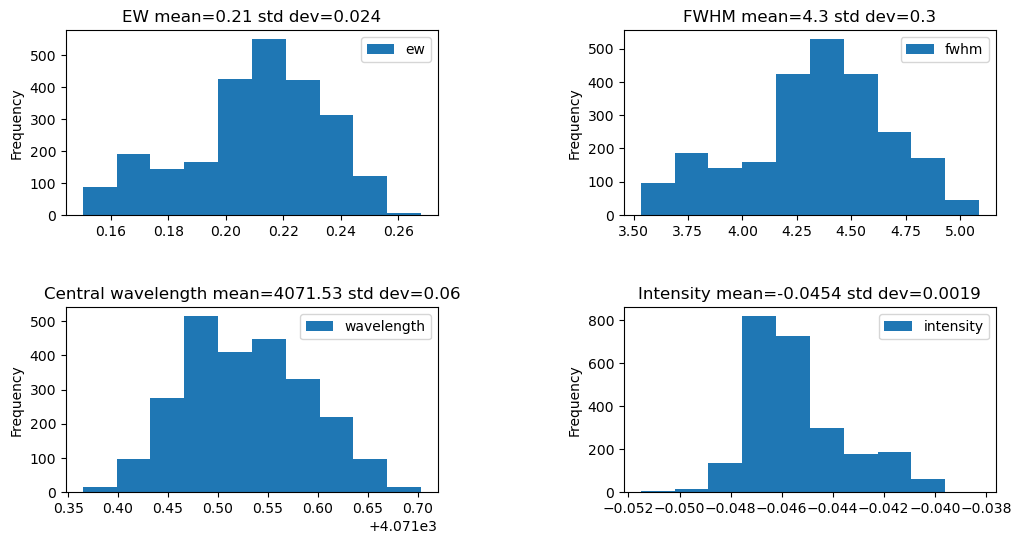

#### Plotting results for O II 4076

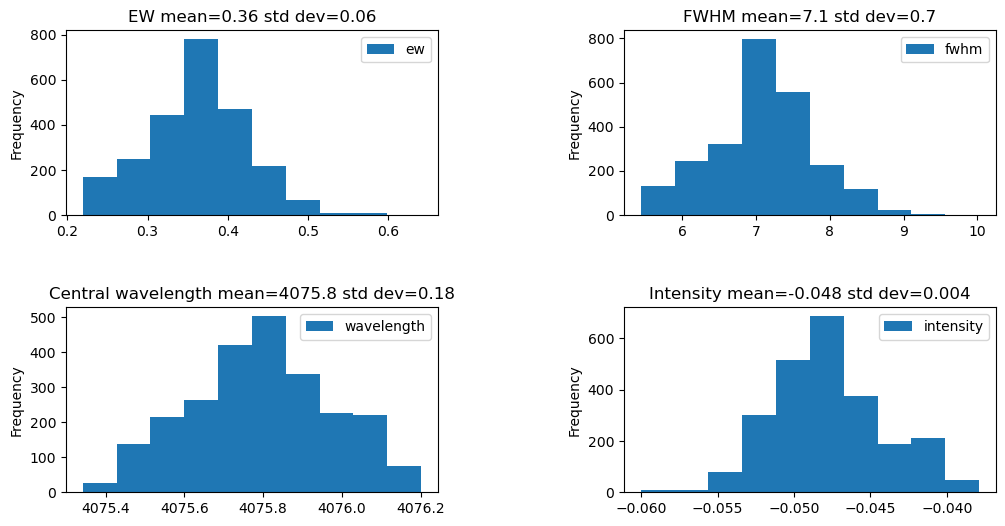

#### Plotting results for O II 4089

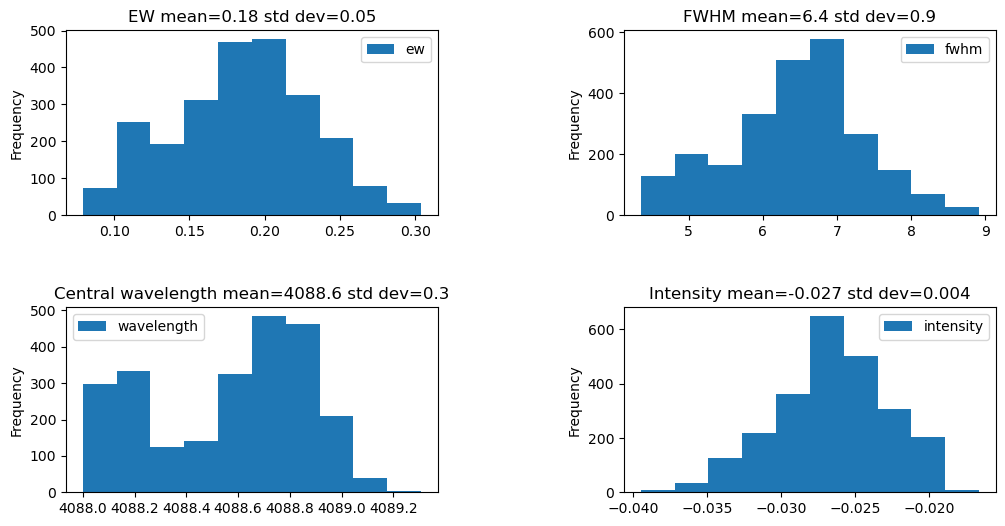

#### Plotting results for H delta

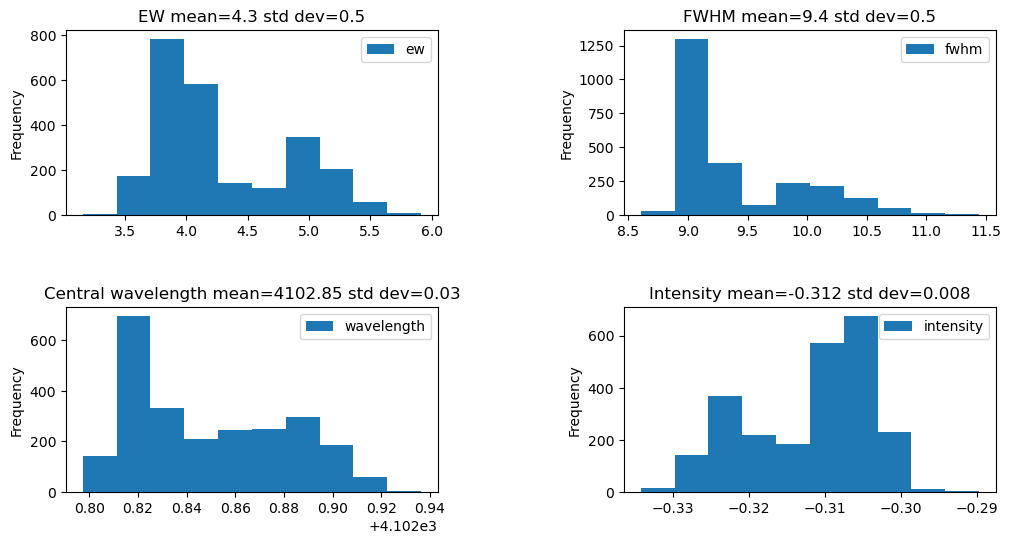

#### Plotting results for He I 4121

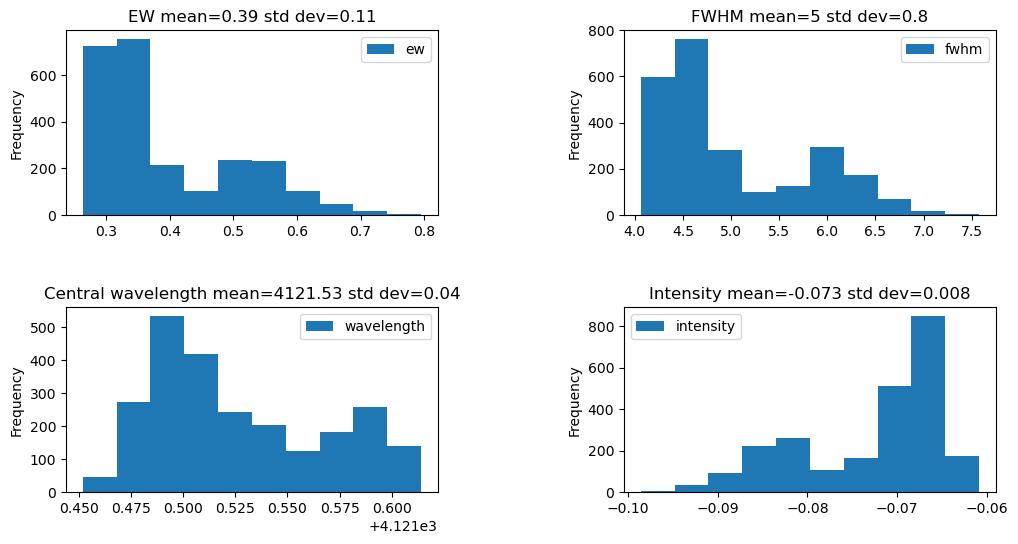

#### Plotting results for O II 4133

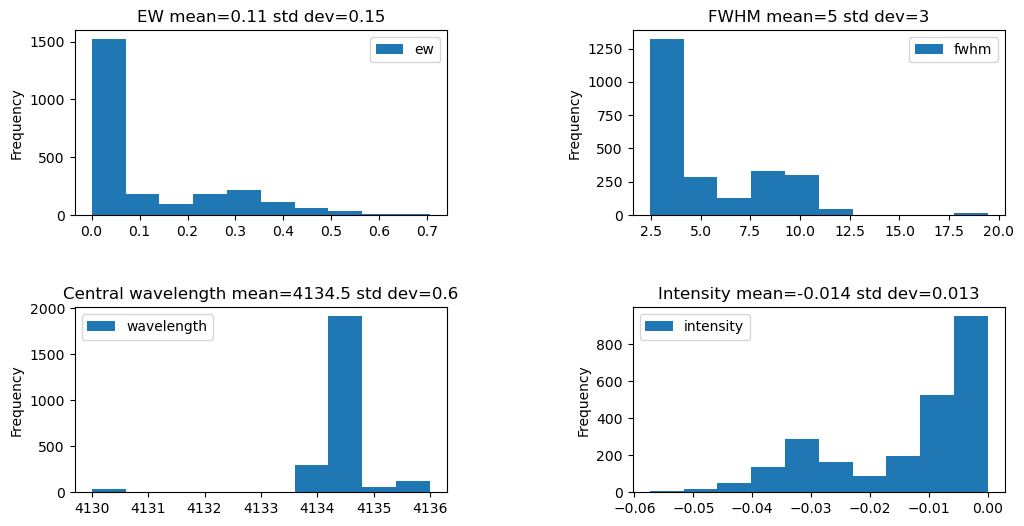

#### Plotting results for He I 4144

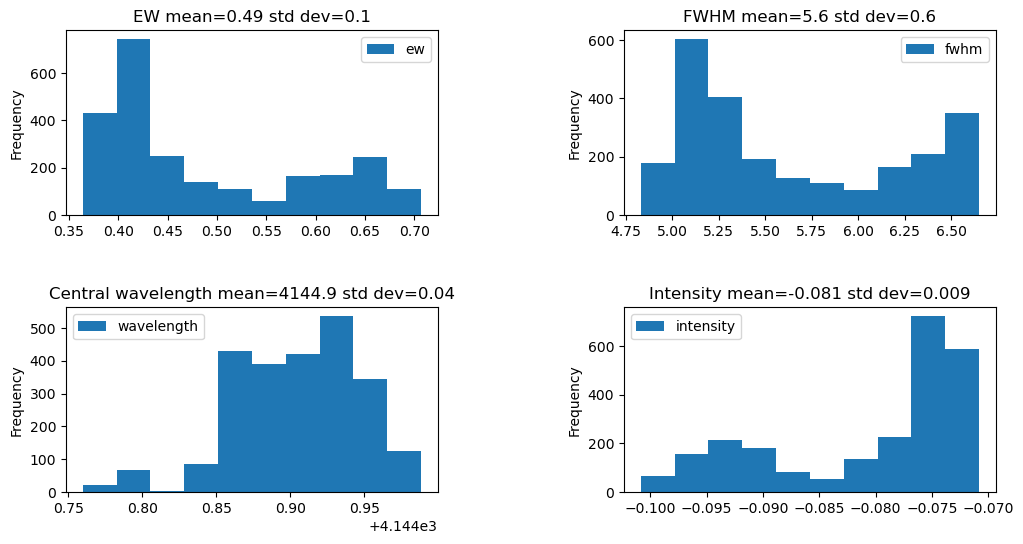

#### Plotting results for Unknown 4153

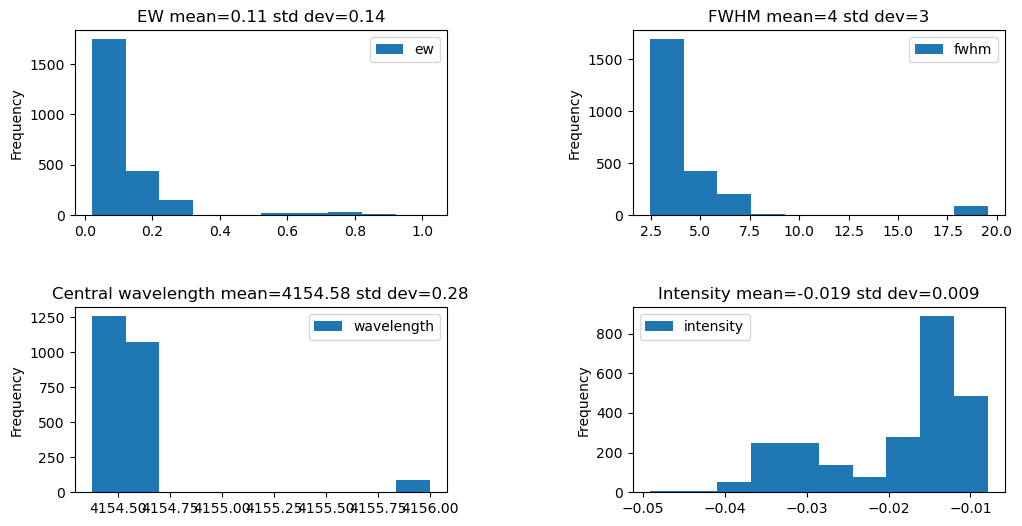

#### H delta / He I 4121-4144 re-fit with best parameters

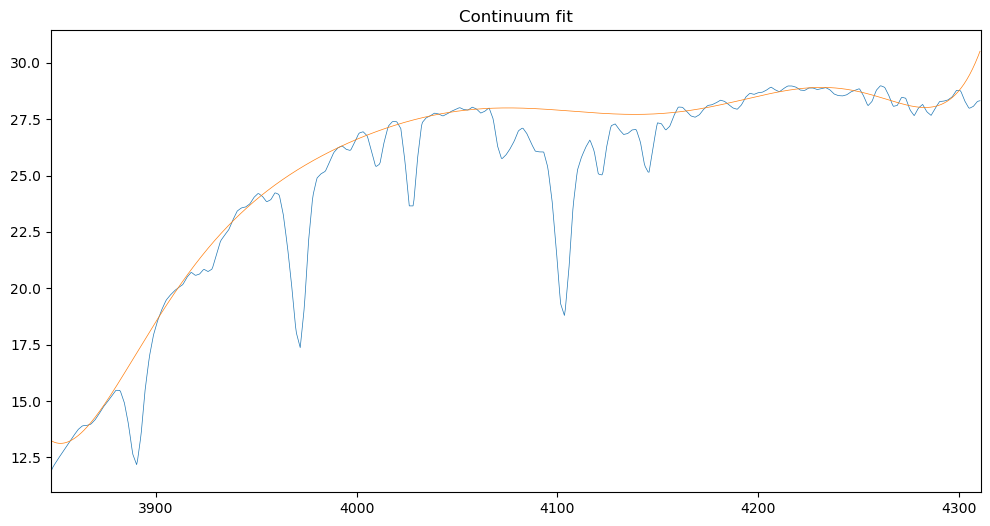

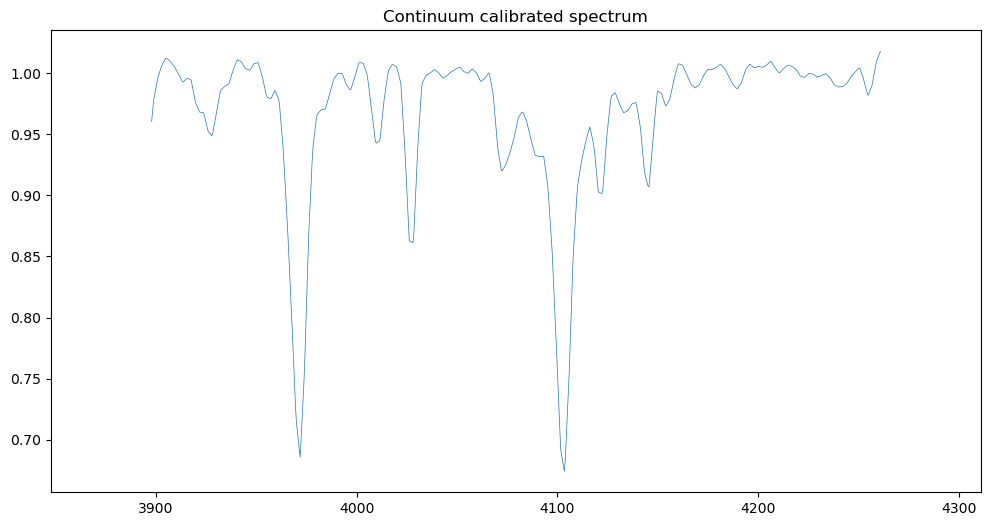

O II 4072 (gauss)
amp = -0.04716765272270853 
mu = 4071.5085648399854 
sigma = 2.0282244168749033 
offset = 1.0 
chi2 = 1.046180904272064


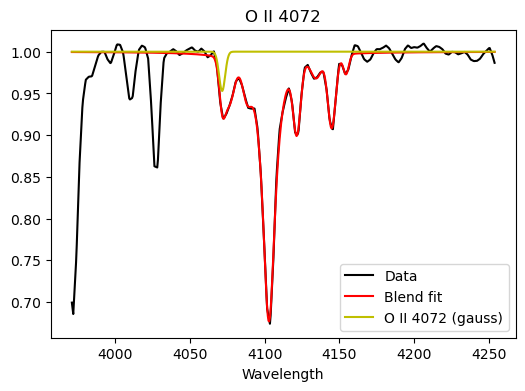

O II 4076 (gauss)
amp = -0.05235258228520688 
mu = 4076.0439376690597 
sigma = 3.422766010963955 
offset = 1.0 
chi2 = 1.046180904272064


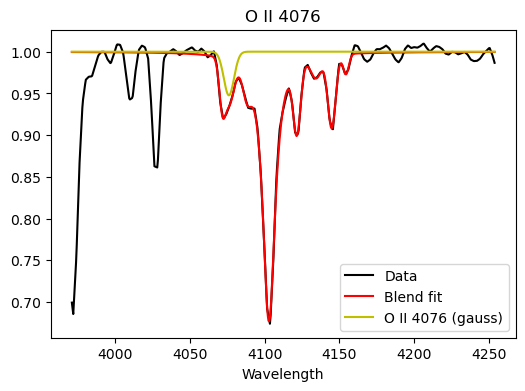

O II 4089 (gauss)
amp = -0.03201886270552588 
mu = 4088.142082908615 
sigma = 2.9035946860719415 
offset = 1.0 
chi2 = 1.046180904272064


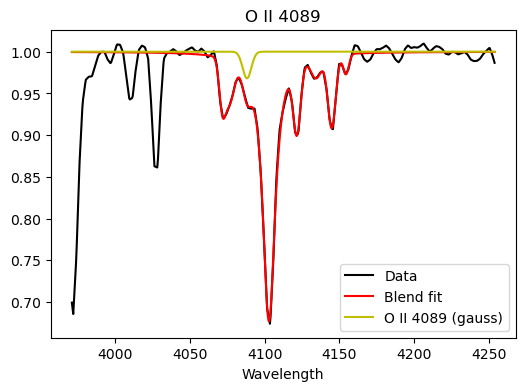

H delta (voigt)
amp = -4.973334265216559 
mu = 4102.864371865406 
sigma = 1.024353764040583 
gamma = 4.688379070150378 
offset = 1.0 
chi2 = 1.046180904272064


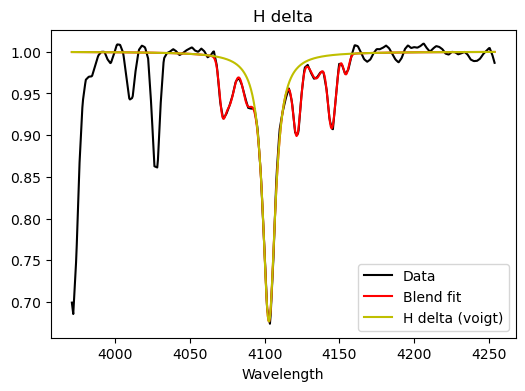

He I 4121 (gauss)
amp = -0.08081152325484948 
mu = 4121.576002473106 
sigma = 2.4656365395402635 
offset = 1.0 
chi2 = 1.046180904272064


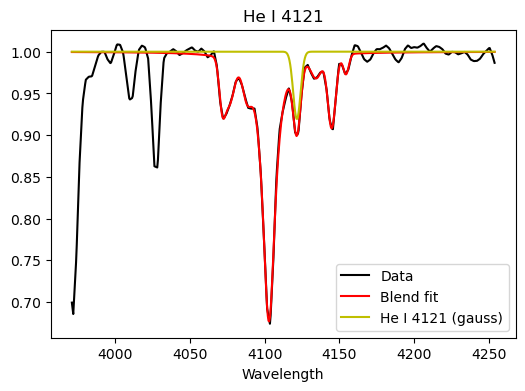

O II 4133 (gauss)
amp = -0.024799439576948627 
mu = 4134.529095048039 
sigma = 3.470872212844607 
offset = 1.0 
chi2 = 1.046180904272064


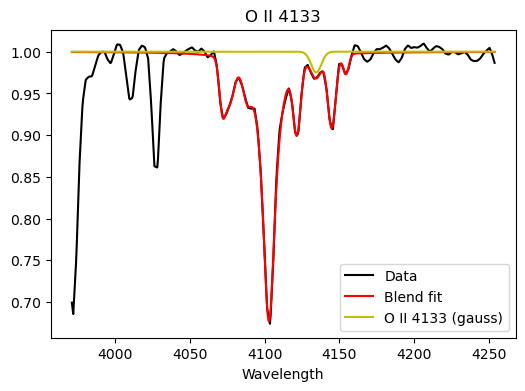

He I 4144 (gauss)
amp = -0.08743343573471815 
mu = 4144.887556350912 
sigma = 2.6485486977232506 
offset = 1.0 
chi2 = 1.046180904272064


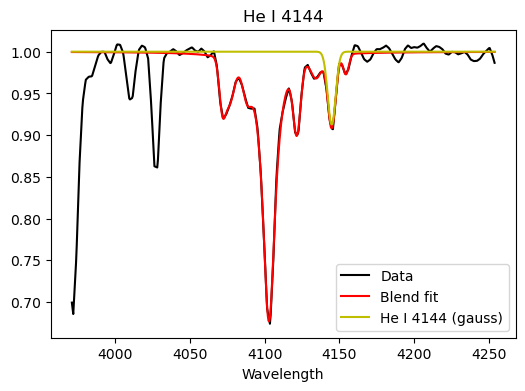

Unknown 4153 (gauss)
amp = -0.024371961537191178 
mu = 4154.421254029841 
sigma = 1.874324491662551 
offset = 1.0 
chi2 = 1.046180904272064


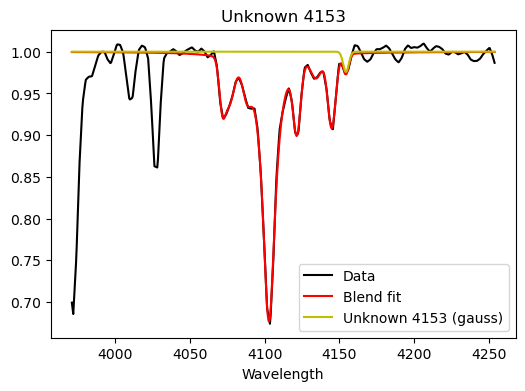

### Measuring H gamma

Blended lines= [{'name': 'H gamma', 'wavelength': 4341.0, 'model': 'voigt'}, {'name': 'O II 4349', 'wavelength': 4349.0}]


#### H gamma preliminary fit

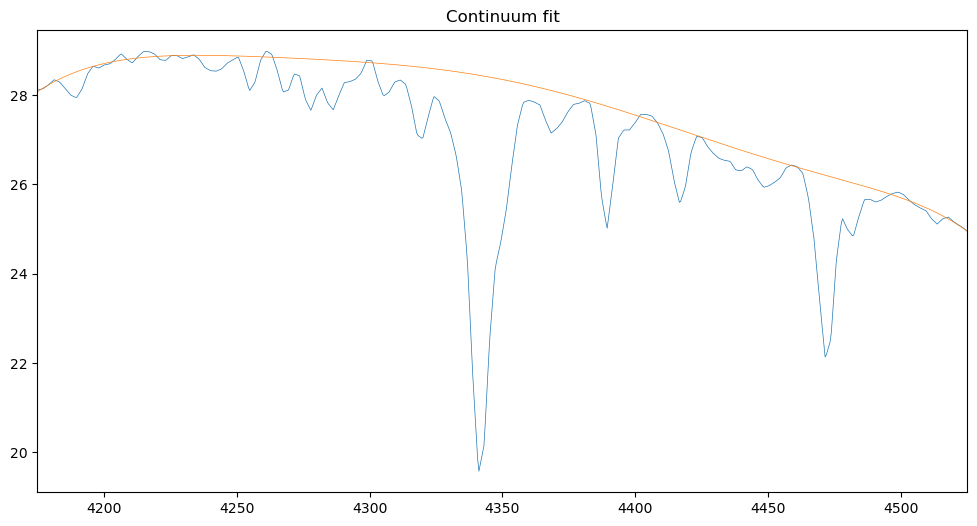

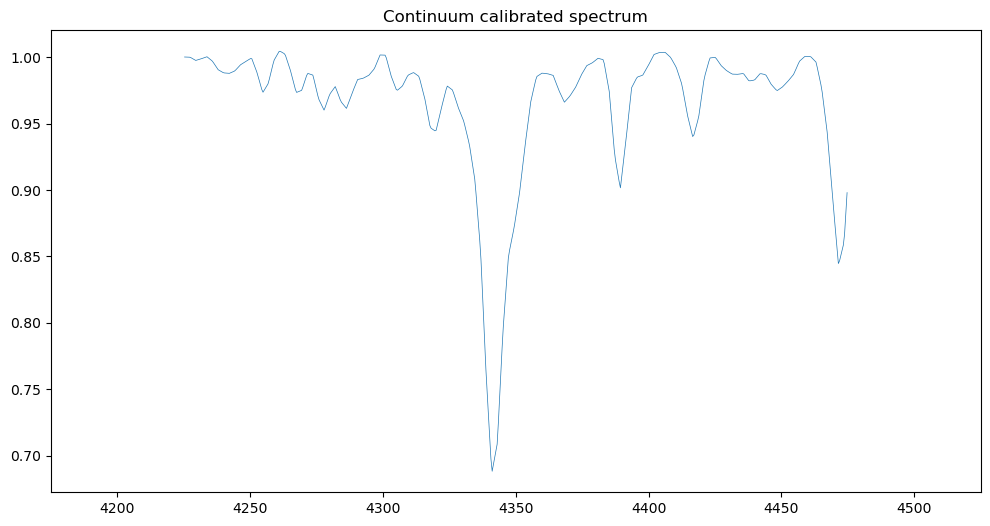

H gamma (voigt)
amp = -4.432720309730383 
mu = 4341.601945257018 
sigma = 1.378190994905005 
gamma = 4.178647193443123 
offset = 1.0 
chi2 = 0.0006231861953434404


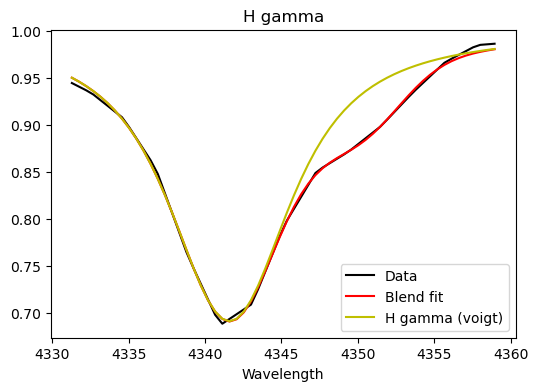

O II 4349 (gauss)
amp = -0.0520057667672562 
mu = 4350.399372433069 
sigma = 2.6983338918052997 
offset = 1.0 
chi2 = 0.0006231861953434404


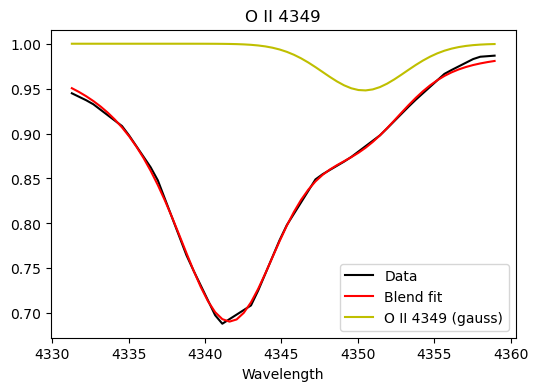

#### H gamma optimization

#### Plotting results for H gamma

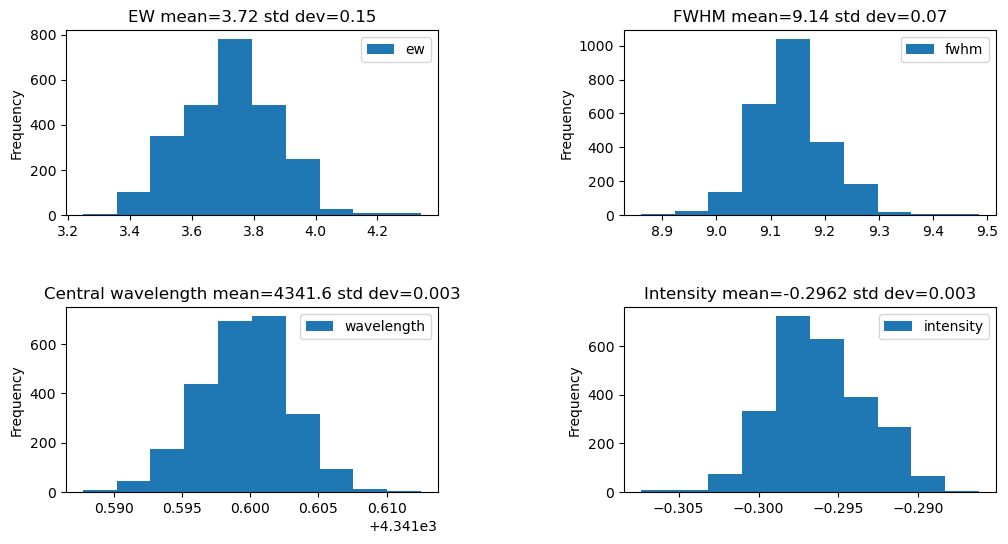

#### Plotting results for O II 4349

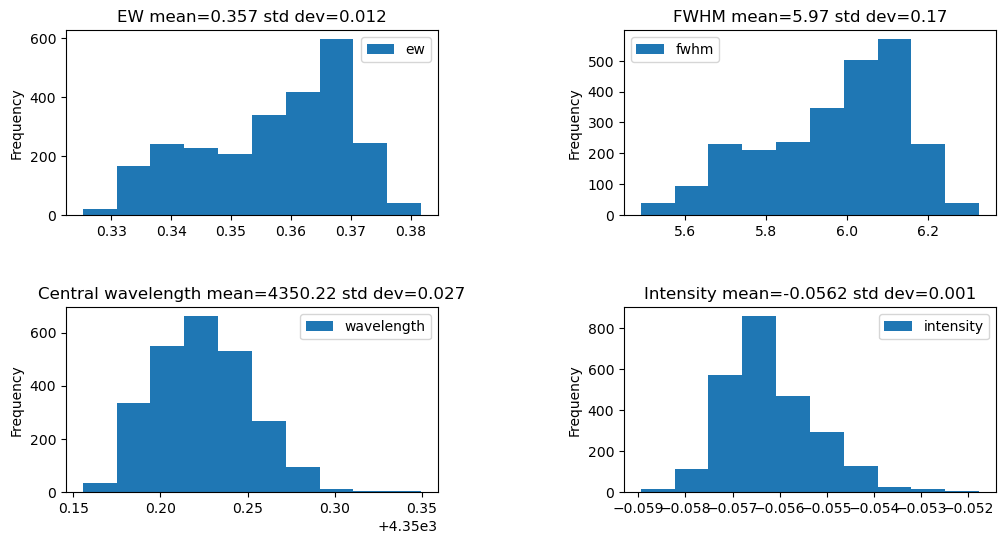

#### H gamma re-fit with best parameters

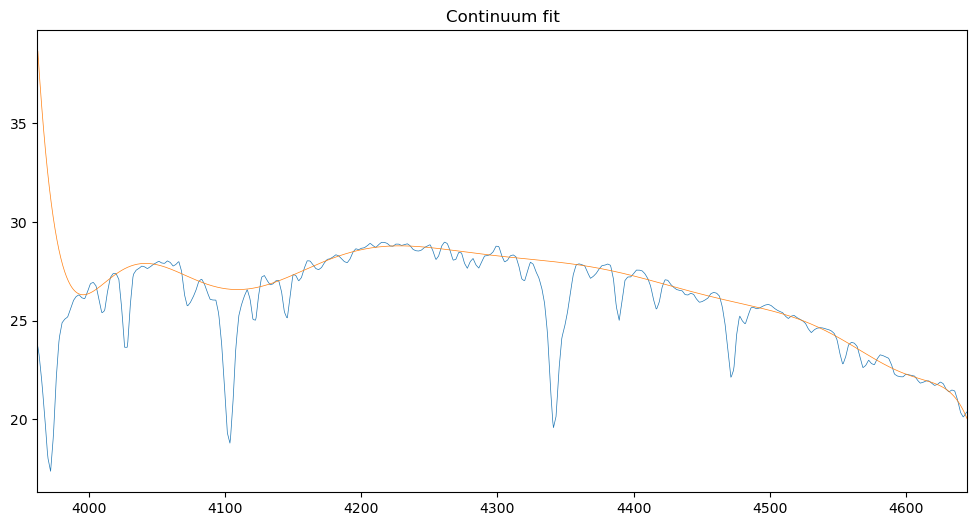

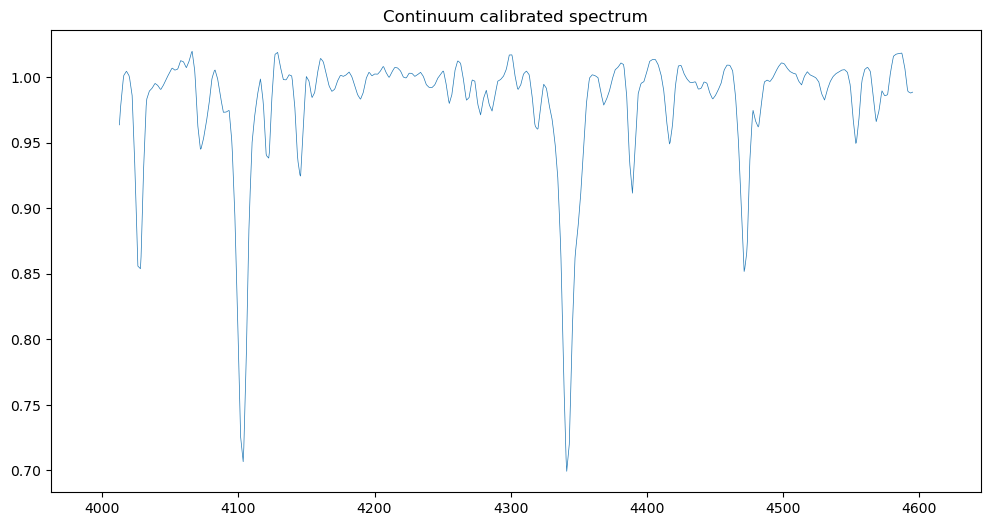

H gamma (voigt)
amp = -3.7256393174975333 
mu = 4341.599864014999 
sigma = 2.2703280404206643 
gamma = 2.930219481543919 
offset = 1.0 
chi2 = 0.0013472332611851941


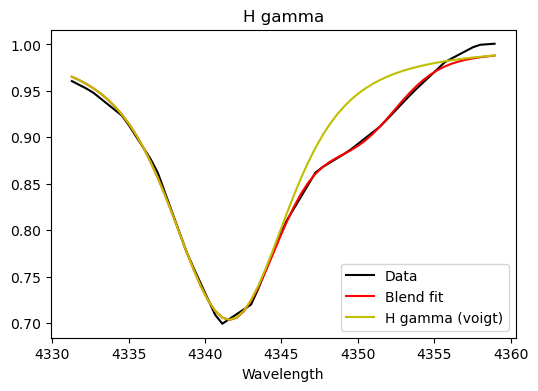

O II 4349 (gauss)
amp = -0.05629513771523571 
mu = 4350.2213139802525 
sigma = 2.5375658589485863 
offset = 1.0 
chi2 = 0.0013472332611851941


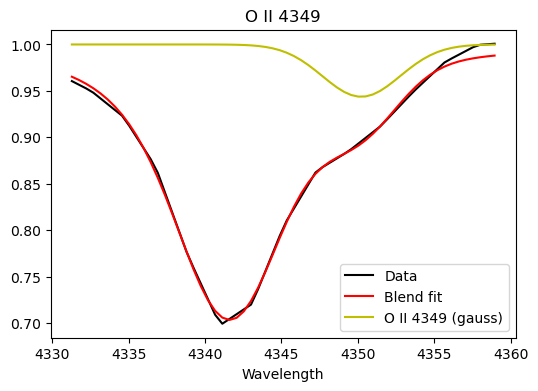

In [30]:
for measuring_blend in measuring_blends:
    results = measure_blend(wl, flux, measuring_blend, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results = pd.concat([summary_results, results], axis=0)

## Summary Results

In [31]:
summary_results = summary_results.sort_values(by=["wavelength"], ascending=False)

summary_results


,line_name,wavelength,delta_wavelength,ew,delta_ew,fwhm,delta_fwhm,intensity,delta_intensity
6,He I 6678,6679.608924,0.020877,0.762763,0.027802,6.660489,0.184103,-0.10757,0.001164
0,H alfa,6564.129111,0.053181,4.272209,0.355319,10.738442,0.88258,-0.253256,0.000658
5,He I 4922,4922.760401,0.012542,0.719011,0.023842,6.572389,0.147462,-0.102757,0.001094
1,H beta,4861.867906,0.011576,3.336836,0.14794,9.670767,0.017345,-0.278893,0.002892
2,He I 4713,4713.933033,0.038695,0.288416,0.026618,5.622954,0.251182,-0.048088,0.002317
1,O II 4705,4705.985273,0.461004,0.222505,0.030742,7.843257,0.874446,-0.026585,0.00143
0,O II 4699,4699.861389,0.32138,0.180119,0.057196,6.462799,0.876248,-0.025552,0.004791
2,Unknown 4490,4489.575296,0.412129,0.027756,0.02812,4.485938,1.563848,-0.004955,0.003017
1,Mg II 4481,4481.656159,0.030561,0.213406,0.019388,5.201336,0.143185,-0.038494,0.002603
0,He I 4471,4471.862303,0.02173,1.121439,0.043144,7.234992,0.175558,-0.145578,0.002098


In [32]:
summary_results.to_csv("line_measured_mirzam_20260206.csv")